# SUNS – zadanie 3: Odhad kalórií z fotografie jedla

**Konvolučné siete, prenos vedomostí, zhlukovanie a Vision Transformer**

Cieľom je odhadnúť `total_calories` v kcal výhradne z RGB fotografie. Riešenie používa všetkých 3 260 dodaných snímok. Číselné údaje o hmotnosti, makroživinách ani ingrediencie nevstupujú do prediktorov. Ingrediencie slúžia na opis dát, kontrolu opakovaných jedál a dodatočnú interpretáciu zhlukov.

**Zvolené možnosti:** transfer learning podľa možnosti 1; porovnanie MLP, SVR a stromového ensemble; nepovinné farebné filtre CNN a malý ViT trénovaný z obrázkov. Vlastné fotografie a viacvýstupová regresia nie sú súčasťou zvoleného rozsahu.

Notebook čítajte a spúšťajte zhora nadol. Vysvetlenie nasleduje v Markdown bunke pod každým logickým blokom. Po audite podozrivého záznamu sme sa rozhodli ponechať všetky dáta a pridať šiestu, robustnú CNN konfiguráciu. Výstupy obsahujú skutočne vypočítané výsledky; záverečné interpretačné bunky sa vzťahujú na uložený beh.

## 0. Prostredie, reprodukovateľnosť a plán experimentu

In [1]:
from pathlib import Path
import os, sys, json, hashlib, random, time, copy, platform, importlib.metadata
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
from IPython.display import display
import scipy.stats as stats
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, TensorDataset
import torchvision
from torchvision import transforms as T
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler, Normalizer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, silhouette_score, davies_bouldin_score
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVR
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
import joblib

ROOT = Path.cwd()
DATA = ROOT / 'data'
ART = ROOT / '.suns3'
ART.mkdir(exist_ok=True)
torch.hub.set_dir(str(ART / 'torch'))
SEED = 42
IMAGE_SIZE = 96
BATCH_SIZE = 64
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
torch.set_num_threads(min(4, os.cpu_count() or 1))
def seed_all(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_all()
if DEVICE.type != 'mps': torch.use_deterministic_algorithms(True, warn_only=True)
def viridis_colors(count):
    return plt.get_cmap('viridis')(np.linspace(.18, .82, count)).tolist()

SPLIT_COLORS = dict(zip(('train', 'val', 'test'), viridis_colors(3)))
sns.set_theme(style='whitegrid', context='notebook', palette=viridis_colors(6),
              rc={'image.cmap': 'viridis'})
plt.rcParams.update({'figure.dpi':115, 'savefig.dpi':160, 'axes.spines.top':False, 'axes.spines.right':False})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', None)
versions = {name: importlib.metadata.version(name) for name in
            ['torch','torchvision','numpy','pandas','scikit-learn','matplotlib','seaborn','Pillow']}
display(pd.Series(versions, name='Verzia').to_frame())
print('Python:', platform.python_version(), '| Zariadenie:', DEVICE, '| Vlákna:', torch.get_num_threads())

,Verzia
torch,2.14.1
torchvision,0.29.2
numpy,2.5.1
pandas,3.0.3
scikit-learn,1.9.0
matplotlib,3.11.0
seaborn,0.13.2
Pillow,12.3.0


Python: 3.14.6 | Zariadenie: mps | Vlákna: 4


**Čo, prečo a ako:** PyTorch implementuje CNN, MLP a transformer, torchvision poskytuje skutočné ImageNet váhy, scikit-learn regresory a zhlukovanie. Fixujeme seed a evidujeme verzie. GPU sa použije, ak je dostupné, inak CPU. `num_workers=0` nižšie umožňuje spoľahlivé spúšťanie priamo z notebooku aj na macOS.

Potrebné balíky možno v zvolenom Jupyter kerneli doplniť príkazom `%pip install torch torchvision numpy pandas scikit-learn matplotlib seaborn pillow scipy joblib`. Nie je súčasťou automatického behu, aby notebook pri každom spustení nemenil prostredie. Dáta patria do `data/`; medzivýsledky a obnoviteľné checkpointy do jedného priečinka `.suns3/`.

**Protokol:** skupinové rozdelenie približne 70/15/15; všetky škálovače regresie sa učia iba na tréningu; výber konfigurácií používa validačné MAE. Finálny transferový regresor navyše musí na validácii zlepšiť aj RMSE vlastnej CNN; spomedzi takých kandidátov vyberáme najnižšie MAE. Test sa otvorí až po uzamknutí všetkých modelov. Zhlukovanie celého datasetu je samostatná opisná úloha a jeho transformácie ani zhluky nevstupujú do regresie.

**Rozsah reprodukovateľnosti:** fixný seed, uložené verzie, split a checkpointy umožňujú obnoviť experiment. Pri MPS nemožno sľúbiť bitovo identické výsledky medzi rôznymi verziami knižníc a hardvéru; preto sú rozhodujúce aj uložené namerané výstupy.

Grafy, tepelné mapy a mapy aktivácií používajú paletu Viridis. Fotografie sa zobrazujú v pôvodných farbách a farebné zobrazenie filtrov kóduje jednotlivé kanály.

## 1. Audit dát a prieskumná analýza

In [2]:
meta_path = DATA / 'metadata.csv'
df = pd.read_csv(meta_path)
with (DATA / 'metadata.json').open() as f: ingredient_records = json.load(f)
ingredient_df = pd.DataFrame(ingredient_records)
required = {'file_name','id','total_calories','total_mass','total_fat','total_carb','total_protein'}
assert required <= set(df.columns)
assert not df['file_name'].duplicated().any() and not df['id'].duplicated().any()
assert not ingredient_df['file_name'].duplicated().any()
assert set(df['file_name']) == set(ingredient_df['file_name'])
assert set(df['id']) == set(ingredient_df['id'])
assert df.select_dtypes('number').notna().all().all()
assert np.isfinite(df.select_dtypes('number').to_numpy()).all()
assert (df['total_calories'] >= 0).all()
expected_files = set(df.file_name)
actual_files = {p.relative_to(DATA).as_posix() for p in (DATA/'images').glob('*.png')}
assert expected_files == actual_files, (expected_files-actual_files, actual_files-expected_files)
df = df.merge(ingredient_df[['file_name','id','ingredients']], on=['file_name','id'], validate='one_to_one')
df['path'] = df.file_name.map(lambda x: DATA/x)
df['n_ingredients'] = df.ingredients.map(len)

def inspect_image(path):
    with Image.open(path) as im:
        im.load()
        return im.size[0], im.size[1], im.mode, hashlib.sha256(im.tobytes()).hexdigest()
with ThreadPoolExecutor(max_workers=4) as pool:
    image_audit = list(pool.map(inspect_image, df.path))
audit_df = pd.DataFrame(image_audit, columns=['width','height','mode','pixel_sha256'])
df = pd.concat([df, audit_df], axis=1)
assert df['mode'].eq('RGB').all(), 'Všetky vstupy musia mať 3 farebné kanály.'
assert df.file_name.notna().all()
# Fingerprint zahŕňa obsah obrazov, metadáta, ingrediencie aj implementačnú verziu protokolu.
DATA_KEY = hashlib.sha256((meta_path.read_text() + json.dumps(ingredient_records, sort_keys=True)
             + ''.join(df.pixel_sha256) + 'suns3-v1').encode()).hexdigest()
display(pd.DataFrame({'počet': [len(df), len(actual_files), df.id.nunique(),
                               df.pixel_sha256.duplicated().sum()]},
                     index=['Záznamy CSV','Obrázky na disku','Jedinečné ID','Opakovaný obsah obrázka']))
display(df[['width','height','mode']].value_counts().rename('počet').to_frame())
display(df.drop(columns=['ingredients','path']).isna().sum().rename('chýba').to_frame())
display(df[['file_name','id','total_calories','total_mass','total_fat','total_carb','total_protein','n_ingredients']].head())

,počet
Záznamy CSV,3260
Obrázky na disku,3260
Jedinečné ID,3260
Opakovaný obsah obrázka,0


,,,počet
width,height,mode,
640,480,RGB,3260


,chýba
file_name,0
id,0
total_calories,0
total_mass,0
total_fat,0
total_carb,0
total_protein,0
n_ingredients,0
width,0
height,0


,file_name,id,total_calories,total_mass,total_fat,total_carb,total_protein,n_ingredients
0,images/dish_1556572657.png,dish_1556572657,41.399998,36.0,3.852,2.268,0.288,1
1,images/dish_1556573514.png,dish_1556573514,6.440000,23.0,0.092,1.219,0.506,1
2,images/dish_1556575014.png,dish_1556575014,71.299995,62.0,6.634,3.906,0.496,1
3,images/dish_1556575083.png,dish_1556575083,27.520000,64.0,0.192,5.760,2.176,1
4,images/dish_1556575124.png,dish_1556575124,4.480000,28.0,0.056,0.952,0.196,1


**Čo, prečo a ako:** párovanie používa cestu a ID, nikdy poradie súborov na disku. Kontroly `assert` odmietnu neúplné, duplicitné alebo nečíselné dáta. Každý obrázok sa skutočne otvorí a dekóduje; kontrolujeme rozlíšenie, RGB režim aj hash pixelov. Rovnaký názov a rovnaký obsah sú dve odlišné kontroly.

**Štruktúra:** `file_name` je relatívna cesta, `id` identifikátor taniera, `total_calories` energia v kcal, `total_mass` hmotnosť v g, `total_fat`, `total_carb`, `total_protein` gramy makroživín. CSV neobsahuje zoznam ingrediencií: ten je v sprievodnom JSON. Každá ingrediencia má `id`, `name`, `grams`, `calories`, `fat`, `carb`, `protein`. `n_ingredients` je odvodený opisný údaj. Žiadny z týchto nutričných atribútov nepoužívame ako vstup modelu.

**Výsledok auditu:** pozri počty a kontrolu chýbajúcich hodnôt nad týmto textom. Pri nezhode notebook zastaví beh; nepáruje ani nevyhadzuje problémové záznamy potichu.

**Nameraný výsledok:** 3 260 záznamov zodpovedá presne 3 260 obrázkom. Všetky majú 640 × 480 pixelov a režim RGB. Nenašli sme chýbajúce hodnoty v CSV, duplicitné ID, duplicitné cesty ani rovnaký pixelový obsah. JSON sa spároval 1 : 1 podľa cesty a ID.

,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
total_calories,3260.0,255.17,219.61,1.15,6.89,80.23,209.29,375.15,646.84,918.55,3943.33
total_mass,3260.0,215.09,161.49,5.00,14.00,92.75,177.00,305.25,500.05,702.46,3051.00
total_fat,3260.0,12.74,13.53,0.00,0.04,1.85,8.87,19.04,39.20,60.39,106.34
total_carb,3260.0,19.40,21.61,0.00,0.25,6.21,15.36,27.54,51.37,68.35,844.57
total_protein,3260.0,18.02,20.05,0.07,0.28,2.14,11.52,28.05,55.20,85.40,147.49
n_ingredients,3260.0,7.32,6.94,1.00,1.00,1.00,4.00,12.00,21.00,26.41,34.00


Najväčší rozdiel total_calories a súčtu ingrediencií: 0.0001 kcal


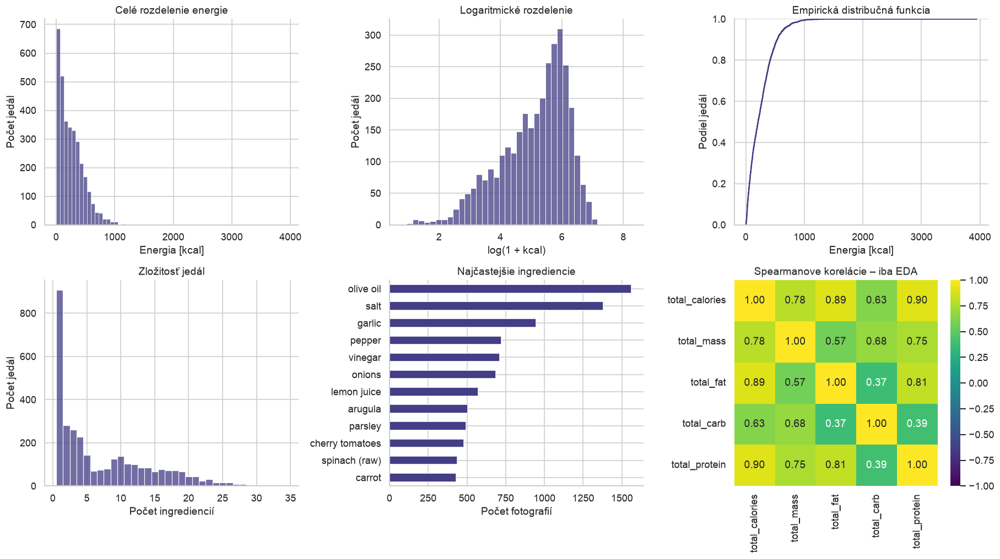

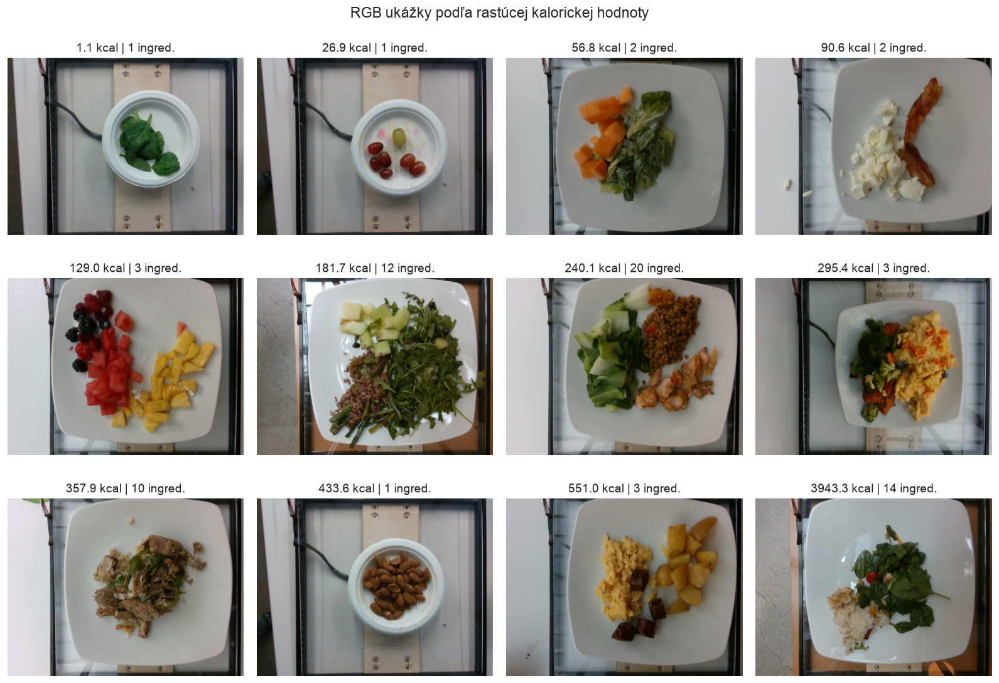

,file_name,total_calories,total_mass,n_ingredients
1057,images/dish_1560974769.png,3943.325195,3051.0,14
2531,images/dish_1565033265.png,1324.084961,625.0,6
1563,images/dish_1562603895.png,1268.157349,517.0,8
2350,images/dish_1564170010.png,1264.548340,831.0,23
2094,images/dish_1563476577.png,1238.033691,857.0,30


In [3]:
ing_rows = []
for row in df.itertuples():
    for ingredient in row.ingredients:
        ing_rows.append({'file_name':row.file_name, **ingredient})
ings = pd.DataFrame(ing_rows)
summary = df[['total_calories','total_mass','total_fat','total_carb','total_protein','n_ingredients']].describe(percentiles=[.01,.25,.5,.75,.95,.99]).T
display(summary.round(2))
ing_calories = ings.groupby('file_name').calories.sum().reindex(df.file_name).to_numpy()
print('Najväčší rozdiel total_calories a súčtu ingrediencií:', round(float(np.max(abs(ing_calories-df.total_calories))), 4), 'kcal')
fig, ax = plt.subplots(2,3, figsize=(16,9))
sns.histplot(df.total_calories, bins=60, ax=ax[0,0]); ax[0,0].set(title='Celé rozdelenie energie',xlabel='Energia [kcal]',ylabel='Počet jedál')
sns.histplot(np.log1p(df.total_calories), bins=40, ax=ax[0,1]); ax[0,1].set(title='Logaritmické rozdelenie',xlabel='log(1 + kcal)',ylabel='Počet jedál')
sns.ecdfplot(data=df,x='total_calories',ax=ax[0,2]); ax[0,2].set(title='Empirická distribučná funkcia',xlabel='Energia [kcal]',ylabel='Podiel jedál')
sns.histplot(df.n_ingredients, discrete=True,ax=ax[1,0]); ax[1,0].set(title='Zložitosť jedál',xlabel='Počet ingrediencií',ylabel='Počet jedál')
top_ingredients = ings.groupby('name').file_name.nunique().nlargest(12)
top_ingredients.sort_values().plot.barh(ax=ax[1,1]); ax[1,1].set(title='Najčastejšie ingrediencie',xlabel='Počet fotografií',ylabel='')
sns.heatmap(df[['total_calories','total_mass','total_fat','total_carb','total_protein']].corr(method='spearman'), annot=True,fmt='.2f',cmap='viridis',vmin=-1,vmax=1,ax=ax[1,2]); ax[1,2].set_title('Spearmanove korelácie – iba EDA')
plt.tight_layout(); plt.show()
# Ukážky naprieč rozsahom cieľa, vrátane extrému, bez odstraňovania odľahlých hodnôt.
show_idx = df.sort_values('total_calories').iloc[np.linspace(0,len(df)-1,12).astype(int)].index
fig, axes = plt.subplots(3,4,figsize=(14,10))
for ax, idx in zip(axes.flat, show_idx):
    with Image.open(df.at[idx,'path']) as im: ax.imshow(im)
    ax.set_title(f"{df.at[idx,'total_calories']:.1f} kcal | {df.at[idx,'n_ingredients']} ingred.")
    ax.axis('off')
plt.suptitle('RGB ukážky podľa rastúcej kalorickej hodnoty'); plt.tight_layout(); plt.show()
display(df.nlargest(5,'total_calories')[['file_name','total_calories','total_mass','n_ingredients']])

**Čo, prečo a ako:** histogram ukazuje početnosť, logaritmická os odhalí aj nízke hodnoty, ECDF podiel jedál pod hranicou a obrazová mriežka spája číslo s reálnym vzhľadom taniera. Korelácie sú opisné: vysoká súvislosť kalórií s hmotnosťou neoprávňuje použiť hmotnosť ako vstup.

**Interpretácia:** rozdelenie je pravostranné. Bežné jedlá sú výrazne menej kalorické než najväčší extrém; MSE a RMSE preto môžu ovplyvniť jednotlivé fotografie viac než MAE. Extrémy ponechávame, pretože bez overenia pôvodného merania ich nemožno vyhlásiť za chybu. Súčty ingrediencií kontrolujú vnútornú konzistentnosť, nie pravdivosť pôvodného merania. Konkrétne `dish_1560974769` má anotovaných 2 991 g bielej ryže, čo tvorí 3 888,3 z celkových 3 943,3 kcal. Fotografia ukazuje oveľa menšiu viditeľnú porciu; ide o podozrenie na chybu anotácie, nie overenú opravu. Záznam ponechávame, nevymýšľame náhradnú hodnotu a jeho vplyv obmedzíme dodatočným Huberovým experimentom. Tento extrém patrí pri fixnom rozdelení do tréningu. Rovnaká farba jedla navyše neprezradí presnú hmotnosť ani skryté množstvo oleja či omáčky. Fotografia zhora neobsahuje priame meranie objemu.

**Namerané rozdelenie:** medián je 209,29 kcal, priemer 255,17 kcal a smerodajná odchýlka 219,61 kcal. Vyšší priemer oproti mediánu zodpovedá pravému chvostu. Priemerné jedlo má 7,32 anotovaných ingrediencií; najčastejšie sú olivový olej a soľ, ktoré však na fotografii nemusia byť jednoznačne viditeľné.

## 2. Rozdelenie bez úniku dát a RGB generátory

,count,mean,std,median,min,max
split,,,,,,
test,466,252.10,207.03,209.29,5.75,1268.16
train,2328,255.54,223.69,209.08,1.15,3943.33
val,466,256.40,211.54,210.47,1.84,1264.55


Jedinečné skupiny: 3029


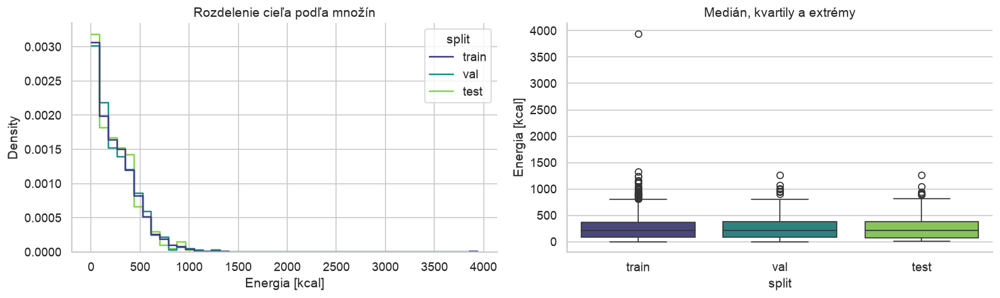

In [4]:
# Rovnaký pixelový obsah ALEBO rovnaká presná kombinácia ingrediencií a gramáží
# musí zostať v jednej časti dát. Union-find zabezpečí aj tranzitívne prepojenia.
parent = np.arange(len(df))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i
def union(a,b):
    a,b = find(a),find(b)
    if a != b: parent[b] = a
recipe_keys = df.ingredients.map(lambda arr: tuple(sorted((x['id'],float(x['grams'])) for x in arr)))
for keys in [df.pixel_sha256, recipe_keys]:
    seen = {}
    for i,key in enumerate(keys):
        if key in seen: union(i,seen[key])
        else: seen[key] = i
groups = np.array([find(i) for i in range(len(df))])
y_all = df.total_calories.to_numpy(dtype=np.float32)
y_bins = pd.qcut(df.total_calories, q=10, labels=False, duplicates='drop').to_numpy()
outer = StratifiedGroupKFold(n_splits=7,shuffle=True,random_state=SEED)
trainval_idx, test_idx = next(outer.split(np.zeros(len(df)),y_bins,groups))
inner = StratifiedGroupKFold(n_splits=6,shuffle=True,random_state=SEED+1)
tr,va = next(inner.split(np.zeros(len(trainval_idx)),y_bins[trainval_idx],groups[trainval_idx]))
train_idx, val_idx = trainval_idx[tr], trainval_idx[va]
SPLITS = {'train':np.sort(train_idx),'val':np.sort(val_idx),'test':np.sort(test_idx)}
assert sum(len(x) for x in SPLITS.values()) == len(df)
assert len(np.unique(np.concatenate(list(SPLITS.values())))) == len(df)
for a,b in [('train','val'),('train','test'),('val','test')]:
    assert not set(groups[SPLITS[a]]) & set(groups[SPLITS[b]])
df['split'] = ''
for name,idx in SPLITS.items(): df.loc[idx,'split'] = name
SPLIT_KEY = hashlib.sha256((DATA_KEY+json.dumps({k:v.tolist() for k,v in SPLITS.items()})).encode()).hexdigest()
y_mean = float(y_all[SPLITS['train']].mean()); y_std = float(y_all[SPLITS['train']].std())
assert y_std > 0
split_summary = df.groupby('split').total_calories.agg(['count','mean','std','median','min','max'])
display(split_summary.round(2)); print('Jedinečné skupiny:', len(set(groups)))
fig, ax = plt.subplots(1,2,figsize=(13,4))
sns.histplot(data=df,x='total_calories',hue='split',hue_order=list(SPLIT_COLORS),palette=SPLIT_COLORS,bins=45,stat='density',common_norm=False,element='step',fill=False,ax=ax[0]); ax[0].set(xlabel='Energia [kcal]',title='Rozdelenie cieľa podľa množín')
sns.boxplot(data=df,x='split',y='total_calories',order=list(SPLIT_COLORS),hue='split',palette=SPLIT_COLORS,legend=False,ax=ax[1]); ax[1].set(ylabel='Energia [kcal]',title='Medián, kvartily a extrémy')
plt.tight_layout(); plt.show()

**Čo, prečo a ako:** približne 1/7 dát tvorí test a 1/6 zo zvyšku validáciu. Kvantilové pásma pomáhajú zachovať zastúpenie nízko aj vysokokalorických jedál. Skupinové obmedzenie má prednosť pred presným percentom. Seed aj prvý fold sú určené vopred; fold nevyberáme podľa úspešnosti.

Zhodný zoznam ingrediencií a gramáží je konzervatívny indikátor opakovania receptu, nie dôkaz totožnej fotografie. Môže spojiť aj rôzne odfotené porcie s rovnakou anotáciou. Rozdelenie obmedzuje únik týchto presných opakovaní, no negarantuje oddelenie všetkých vizuálne podobných jedál alebo celých časových sérií Nutrition5k. Nemáme spoľahlivý identifikátor takej série. Ingrediencie sa používajú iba na toto obmedzenie, nikdy ako vstup regresie.

**Výsledok:** tabuľka a grafy ukazujú skutočné veľkosti a rozdiely distribúcií. Každý index označuje celý pár obrázok–cieľ. Priemer aj smerodajná odchýlka cieľa sú vypočítané výhradne z tréningu.

**Namerané rozdelenie množín:** 2 328 tréningových, 466 validačných a 466 testových obrázkov, teda približne 71,4 % / 14,3 % / 14,3 %. Vzniklo 3 029 skupín. Ich prieniky medzi množinami sú prázdne a všetkých 3 260 párov je zaradených práve raz.

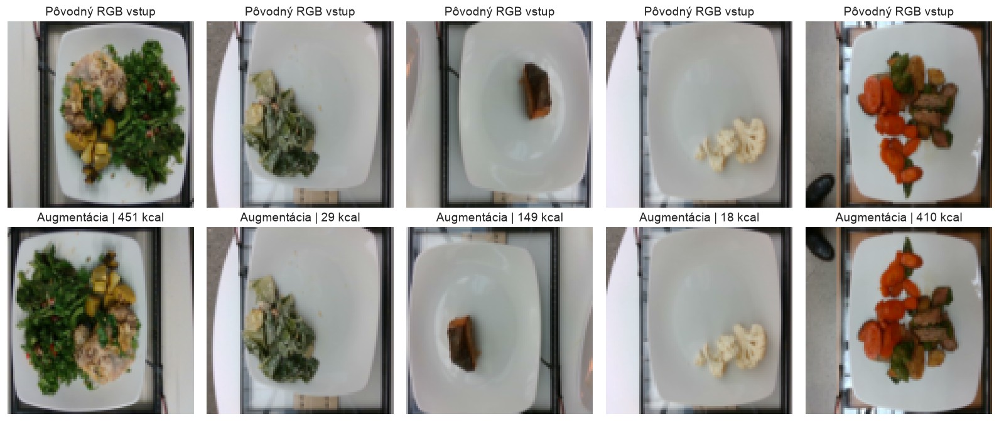

Vstup batchu: (64, 3, 96, 96) | cieľ: (64,)


In [5]:
# Dekódovanie raz do RAM znižuje cenu opakovaných epoch; stále ide o RGB obrázky.
def small_rgb(path):
    with Image.open(path) as im:
        return np.asarray(im.convert('RGB').resize((IMAGE_SIZE,IMAGE_SIZE),Image.Resampling.BILINEAR)).copy()
with ThreadPoolExecutor(max_workers=4) as pool:
    rgb_small = np.stack(list(pool.map(small_rgb,df.path)))
images_tensor = torch.from_numpy(rgb_small).permute(0,3,1,2).contiguous()
IMAGENET_MEAN = torch.tensor([.485,.456,.406]).view(3,1,1)
IMAGENET_STD = torch.tensor([.229,.224,.225]).view(3,1,1)
class PlateDataset(Dataset):
    def __init__(self, indices, augment=False): self.indices=np.array(indices); self.augment=augment
    def __len__(self): return len(self.indices)
    def __getitem__(self,k):
        idx = int(self.indices[k])
        x = images_tensor[idx].float()/255.
        if self.augment:
            # Celý tanier zostáva vo výreze; rotácia o 90° neodreže ani nevytvorí porciu.
            x = torch.rot90(x,int(torch.randint(0,4,()).item()),[1,2])
            if torch.rand(()) < .5: x = x.flip(2)
        x = (x-IMAGENET_MEAN)/IMAGENET_STD
        target = (y_all[idx]-y_mean)/y_std
        return x, torch.tensor(target,dtype=torch.float32), idx

def image_loader(split,augment=False,shuffle=False,epoch=0):
    return DataLoader(PlateDataset(SPLITS[split],augment),batch_size=BATCH_SIZE,shuffle=shuffle,
                      generator=torch.Generator().manual_seed(SEED+epoch),num_workers=0,drop_last=False)
train_loader = image_loader('train',augment=True,shuffle=True)
val_loader = image_loader('val'); test_loader = image_loader('test')
x_example, y_example, example_ids = next(iter(train_loader))
assert x_example.shape[1:] == (3,IMAGE_SIZE,IMAGE_SIZE)
assert np.allclose(y_example.numpy()*y_std+y_mean,y_all[example_ids.numpy()],atol=1e-3)
fig, axes = plt.subplots(2,5,figsize=(14,6))
for k in range(5):
    idx=int(example_ids[k]); axes[0,k].imshow(rgb_small[idx]); axes[0,k].axis('off'); axes[0,k].set_title('Pôvodný RGB vstup')
    restored=(x_example[k]*IMAGENET_STD+IMAGENET_MEAN).permute(1,2,0).clamp(0,1)
    axes[1,k].imshow(restored); axes[1,k].axis('off'); axes[1,k].set_title(f'Augmentácia | {y_all[idx]:.0f} kcal')
plt.tight_layout(); plt.show()
print('Vstup batchu:',tuple(x_example.shape),'| cieľ:',tuple(y_example.shape))

**Čo, prečo a ako:** `Dataset` vracia spoločne obrázok, správny cieľ aj pôvodný index. Tréning sa mieša, validácia a test nie. Pri vyhodnotení navyše overíme vrátené indexy. Zmenšenie na 96 × 96 šetrí výpočty; pomer strán sa zmení rovnako pre všetky snímky. Všetky tri kanály zostávajú zachované.

Normalizácia najprv prevedie intenzity na 0–1 a potom použije konštanty ImageNet. Neučia sa na našom teste a umožnia konzistentnú farebnú mierku. Kalórie štandardizujeme tréningovým priemerom a odchýlkou, ale metriky vždy počítame po spätnom prevode do kcal. Tréningové rotácie a zrkadlenie nemenia porciu; náhodný orez by ju mohol zmeniť, preto ho pri vlastnej CNN nepoužívame. Spodný rad je farebná spätná vizualizácia skutočne augmentovaného batchu.

**Normalizácia vo vzorci:** pre farbu $c$ používame $x'_c=(x_c/255-\mu_c)/\sigma_c$, kde $\mu_c,\sigma_c$ sú konštanty ImageNet. Cieľ je $z=(y-\mu_{\mathrm{train}})/\sigma_{\mathrm{train}}$ a spätný prevod $\hat y=\hat z\,\sigma_{\mathrm{train}}+\mu_{\mathrm{train}}$. Preto model optimalizuje numericky stabilnejšiu mierku, ale reportované chyby zostávajú v kcal.

## 3. Vlastná konvolučná sieť a šesť cielených konfigurácií

In [6]:
class CalorieCNN(nn.Module):
    def __init__(self,width=16,dropout=.25):
        super().__init__()
        blocks=[]; inc=3
        for outc in [width,2*width,4*width]:
            blocks += [nn.Conv2d(inc,outc,3,padding=1,bias=False),nn.BatchNorm2d(outc),nn.ReLU(),nn.MaxPool2d(2)]
            inc=outc
        self.features=nn.Sequential(*blocks)
        self.head=nn.Sequential(nn.AdaptiveAvgPool2d((3,3)),nn.Flatten(),nn.Linear(inc*9,96),
                                nn.ReLU(),nn.Dropout(dropout),nn.Linear(96,1))
    def forward(self,x): return self.head(self.features(x)).squeeze(-1)

CNN_CONFIGS = [
    dict(name='C1 základ',width=16,dropout=.25,lr=1e-3,weight_decay=1e-4,augment=True),
    dict(name='C2 nižší krok',width=16,dropout=.25,lr=3e-4,weight_decay=1e-4,augment=True),
    dict(name='C3 silnejší dropout',width=16,dropout=.45,lr=1e-3,weight_decay=1e-4,augment=True),
    dict(name='C4 väčšia kapacita',width=24,dropout=.25,lr=1e-3,weight_decay=1e-4,augment=True),
    dict(name='C5 silnejší weight decay',width=16,dropout=.25,lr=1e-3,weight_decay=1e-2,augment=True),
    dict(name='C6 robustná Huber',width=16,dropout=.25,lr=1e-3,weight_decay=1e-4,augment=True,loss='huber'),
]
display(pd.DataFrame(CNN_CONFIGS).fillna({'loss':'mse'}).set_index('name'))
print(CalorieCNN())
print('Počet parametrov:',sum(p.numel() for p in CalorieCNN().parameters()))

def metrics(y,p):
    y=np.asarray(y); p=np.asarray(p)
    assert y.shape == p.shape and np.isfinite(p).all()
    mse=mean_squared_error(y,p)
    return {'MSE':float(mse),'MAE':float(mean_absolute_error(y,p)),
            'RMSE':float(np.sqrt(mse)),'R2':float(r2_score(y,p))}

@torch.inference_mode()
def predict_torch(model,loader):
    model.eval(); pred=[]; target=[]; ids=[]
    for x,y,idx in loader:
        pred.append(model(x.to(DEVICE)).cpu().numpy()*y_std+y_mean)
        target.append(y.numpy()*y_std+y_mean); ids.append(idx.numpy())
    return np.concatenate(target),np.concatenate(pred),np.concatenate(ids)

# Jediný checkpoint súbor uchováva všetky obrazové experimenty aj posledný stav na obnovu.
RUN_FILE=ART/'image_runs.pt'
RUNS=torch.load(RUN_FILE,map_location='cpu',weights_only=False) if RUN_FILE.exists() else {}
def cpu_state(model): return {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
def save_runs():
    temp=RUN_FILE.with_suffix('.tmp'); torch.save(RUNS,temp); temp.replace(RUN_FILE)

def fit_image_model(name, factory, config, max_epochs=90,patience=18):
    signature=hashlib.sha256((SPLIT_KEY+json.dumps(config,sort_keys=True)+'image-training-v1').encode()).hexdigest()
    old=RUNS.get(name,{})
    # Kompatibilita skorších checkpointov rovnakého tréningového protokolu.
    legacy={hashlib.sha256((SPLIT_KEY+json.dumps(config,sort_keys=True)+str(e)+str(p)).encode()).hexdigest()
            for e,p in [(90,18),(120,25)]}
    if old.get('signature') in legacy: old['signature']=signature
    if old.get('signature') != signature: old={}
    seed_all(); model=factory().to(DEVICE)
    optimizer=torch.optim.AdamW(model.parameters(),lr=config['lr'],weight_decay=config['weight_decay'])
    scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='min',factor=.5,patience=6,min_lr=1e-6)
    if old:
        if old.get('complete'):
            model.load_state_dict(old['best_state']); print(name,'– načítaný hotový checkpoint',flush=True)
            return model,old
        model.load_state_dict(old['last_state']); optimizer.load_state_dict(old['optimizer']); scheduler.load_state_dict(old['scheduler'])
    history=old.get('history',[]); best=old.get('best_val_mae',np.inf)
    best_state=old.get('best_state'); best_epoch=old.get('best_epoch',0)
    stale=old.get('stale',0); start=time.perf_counter()
    for epoch in range(len(history),max_epochs):
        seed_all(SEED+epoch); model.train(); total=0.; seen=0
        for x,y,_ in image_loader('train',augment=config['augment'],shuffle=True,epoch=epoch):
            x=x.to(DEVICE); y=y.to(DEVICE); optimizer.zero_grad(set_to_none=True)
            output=model(x)
            loss=(nn.functional.huber_loss(output,y,delta=.5) if config.get('loss')=='huber'
                  else nn.functional.mse_loss(output,y))
            assert torch.isfinite(loss), 'Nečíselná strata'
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),5.); optimizer.step()
            total+=nn.functional.mse_loss(output.detach(),y).item()*len(y); seen+=len(y)
        yt,pt,_=predict_torch(model,image_loader('train'))
        yv,pv,_=predict_torch(model,image_loader('val'))
        mt,mv=metrics(yt,pt),metrics(yv,pv); scheduler.step(mv['MAE'])
        row={'epoch':epoch+1,'optimization_mse':total/seen*y_std**2,
             'train_MAE':mt['MAE'],'train_RMSE':mt['RMSE'],'val_MAE':mv['MAE'],'val_RMSE':mv['RMSE'],
             'lr':optimizer.param_groups[0]['lr']}
        history.append(row)
        if mv['MAE'] < best-.05:
            best=mv['MAE']; best_epoch=epoch+1; best_state=cpu_state(model); stale=0
        else: stale+=1
        entry=dict(signature=signature,config=config,history=history,best_val_mae=best,best_epoch=best_epoch,
                   best_state=best_state,last_state=cpu_state(model),optimizer=optimizer.state_dict(),
                   scheduler=scheduler.state_dict(),stale=stale,complete=False)
        RUNS[name]=entry; save_runs()
        if (epoch+1)%5==0 or epoch==0:
            print(f"{name} | epocha {epoch+1:3d} | train MAE {mt['MAE']:.1f} | val MAE {mv['MAE']:.1f} kcal | {time.perf_counter()-start:.0f} s",flush=True)
        if stale>=patience: break
    RUNS[name]['complete']=True; save_runs()
    model.load_state_dict(best_state)
    print(name,'| najlepšia epocha:',best_epoch,'| val MAE:',round(best,2),flush=True)
    return model,RUNS[name]

,width,dropout,lr,weight_decay,augment,loss
name,,,,,,
C1 základ,16,0.25,0.0010,0.0001,True,mse
C2 nižší krok,16,0.25,0.0003,0.0001,True,mse
C3 silnejší dropout,16,0.45,0.0010,0.0001,True,mse
C4 väčšia kapacita,24,0.25,0.0010,0.0001,True,mse
C5 silnejší weight decay,16,0.25,0.0010,0.0100,True,mse
C6 robustná Huber,16,0.25,0.0010,0.0001,True,huber


CalorieCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (head): Sequential(
    (0): AdaptiveAvgPool2d(output_size=(3, 3))
    (1): Flatten(start_dim=

**Čo, prečo a ako:** sieť má tri konvolučné vrstvy 3 × 3. Skoré vrstvy hľadajú farebné prechody a lokálne štruktúry, hlbšie skladajú zložitejšie vzory. Pooling znižuje rozlíšenie. Priestorový priemer do mriežky 3 × 3 ponechá hrubú informáciu o rozložení a porcii; regresná hlava vracia jedno číslo.

Používame viac než dve požadované techniky: BatchNorm stabilizuje aktivácie, dropout obmedzuje spoluzávislosť neurónov, AdamW penalizuje veľké váhy a augmentácia obmedzuje učenie orientácie taniera. Každá konfigurácia mení voči C1 jeden faktor; C6 nahrádza MSE Huberovou stratou s hranicou 0,5 tréningovej smerodajnej odchýlky (približne 112 kcal). Pri menších reziduáloch sa správa kvadraticky, pri väčších lineárne, a preto obmedzuje vplyv extrémneho záznamu bez jeho vymazania. Výber C6 bol rozhodnutý pri audite dát ešte pred testovým vyhodnotením. experiment je preto interpretovateľný. Všetky používajú tie isté dáta, seed inicializácie a základný limit 90 epoch. Ak má validačný víťaz najlepší checkpoint v posledných 18 epochách tohto limitu, pokračujeme z jeho checkpointu najviac do 150 epoch, aby sme overili ustálenie učenia. Ostatné konfigurácie už nemeníme; pravidlo používa iba validáciu a platí pred otvorením testu. Validačné MAE riadi early stopping aj zníženie kroku učenia.

Tréningová a validačná krivka sa počítajú v `eval()` režime bez augmentácie, aby ich rozdiel nespôsoboval dropout alebo rôzne transformácie. Optimalizačná MSE je samostatná. Pri prerušení sa obnoví posledná epocha aj optimalizátor, pri predikcii sa vrátia váhy s najlepším validačným MAE. Test tu ešte nepoužívame.

**Robustná strata:** pre rozdiel v štandardizovaných kalóriách $e=z-\hat z$ je Huberova strata $L_\delta(e)=\tfrac12 e^2$ pri $|e|\leq\delta$ a $L_\delta(e)=\delta(|e|-\tfrac12\delta)$ inak, s $\delta=0{,}5$. Derivácia veľkých chýb už nerastie úmerne ich veľkosti, preto extrém neovládne gradient tak silno ako pri MSE. Aj pri tomto tréningu ukladáme optimalizačnú MSE, aby bola diagnostika medzi konfiguráciami porovnateľná.

C1 základ – načítaný hotový checkpoint


C2 nižší krok – načítaný hotový checkpoint


C3 silnejší dropout – načítaný hotový checkpoint


C4 väčšia kapacita – načítaný hotový checkpoint


C5 silnejší weight decay – načítaný hotový checkpoint


C6 robustná Huber – načítaný hotový checkpoint


,model,best_epoch,epochs,val_MAE,parameters
0,C1 základ,103,121,72.602,79185
4,C5 silnejší weight decay,87,90,74.704,79185
5,C6 robustná Huber,89,90,76.196,79185
3,C4 väčšia kapacita,44,62,76.542,135961
2,C3 silnejší dropout,85,90,78.382,79185
1,C2 nižší krok,77,90,80.934,79185


CNN vybraná iba podľa validácie: C1 základ


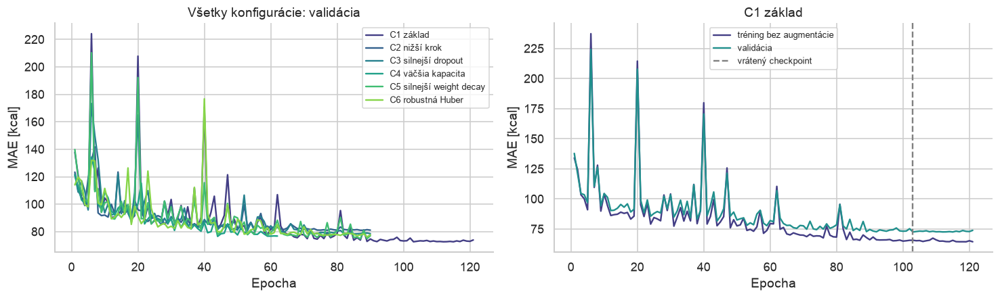

In [7]:
cnn_models={}; cnn_runs={}
for cfg in CNN_CONFIGS:
    model,run=fit_image_model(cfg['name'],lambda c=cfg:CalorieCNN(c['width'],c['dropout']),cfg)
    cnn_models[cfg['name']]=model.to('cpu'); cnn_runs[cfg['name']]=run
best_cnn_name=min(cnn_runs,key=lambda name:cnn_runs[name]['best_val_mae'])
# Ak víťaz stále zlepšuje validáciu na konci základného rozpočtu, overíme plateau.
# Toto pravidlo sa aplikuje pred testom a nemení dáta ani konfiguráciu siete.
provisional=cnn_runs[best_cnn_name]
if (not provisional.get('refined',False) and len(provisional['history'])>=90
        and provisional['best_epoch']>=len(provisional['history'])-18):
    cfg=next(c for c in CNN_CONFIGS if c['name']==best_cnn_name)
    RUNS[best_cnn_name]['complete']=False
    model,run=fit_image_model(best_cnn_name,lambda c=cfg:CalorieCNN(c['width'],c['dropout']),cfg,max_epochs=150)
    RUNS[best_cnn_name]['refined']=True; save_runs()
    cnn_models[best_cnn_name]=model.to('cpu');cnn_runs[best_cnn_name]=run
best_cnn_name=min(cnn_runs,key=lambda name:cnn_runs[name]['best_val_mae'])
best_cnn=cnn_models[best_cnn_name].to(DEVICE)
cnn_validation=pd.DataFrame([{'model':name,'best_epoch':r['best_epoch'],'epochs':len(r['history']),
                            'val_MAE':r['best_val_mae'],'parameters':sum(p.numel() for p in cnn_models[name].parameters())}
                            for name,r in cnn_runs.items()]).sort_values('val_MAE')
display(cnn_validation.round(3)); print('CNN vybraná iba podľa validácie:',best_cnn_name)
fig,axes=plt.subplots(1,2,figsize=(13,4))
for (name, run), color in zip(cnn_runs.items(), viridis_colors(len(cnn_runs))):
    h = pd.DataFrame(run['history'])
    axes[0].plot(h.epoch, h.val_MAE, label=name, color=color)
h=pd.DataFrame(cnn_runs[best_cnn_name]['history'])
axes[0].set(title='Všetky konfigurácie: validácia',xlabel='Epocha',ylabel='MAE [kcal]'); axes[0].legend(fontsize=8)
axes[1].plot(h.epoch,h.train_MAE,label='tréning bez augmentácie',color=SPLIT_COLORS['train'])
axes[1].plot(h.epoch,h.val_MAE,label='validácia',color=SPLIT_COLORS['val'])
axes[1].axvline(cnn_runs[best_cnn_name]['best_epoch'],ls='--',color='grey',label='vrátený checkpoint')
axes[1].set(title=best_cnn_name,xlabel='Epocha',ylabel='MAE [kcal]'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Čo, prečo a ako:** šesť behov je skutočne natrénovaných. Ukladáme ich kompletné krivky, ale pri detailnej diagnostike sa sústredíme na validačného víťaza. Zvislá čiara označuje uložené najlepšie váhy, nie nevyhnutne poslednú epochu.

**Ako posudzujeme učenie:** súčasne vysoká tréningová aj validačná chyba oproti konštantnému baseline naznačuje podtrénovanie; klesajúca tréningová chyba pri rastúcej validačnej chybe signalizuje pretrénovanie. Early stopping zmierňuje druhý problém, sám osebe však nedokazuje optimálnu kapacitu. Konečný verdikt opierame aj o baseline, reziduály a rozdiel metrík v závere. Absolútnu neprítomnosť oboch javov nemožno z jedného malého datasetu dokázať.

**Nameraný výsledok:** podľa validačného MAE vyhrala konfigurácia **C1 základ**, checkpoint z epochy 103 z celkových 121 vykonaných epoch. MAE tohto checkpointu je 65.69 kcal na tréningu a 72.60 kcal na validácii. Rozdiel 6.91 kcal hodnotíme spolu s priebehmi a s vplyvom podozrivej anotácie, nie ako samostatný dôkaz generalizácie.

**Interpretácia priebehu:** skoré výrazné špičky zasahujú tréning aj validáciu naraz. To nezodpovedá typickému obrazu pretrénovania, pri ktorom sa zlepšuje iba tréning a validácia sa zhoršuje. Možnými príčinami sú prechodná nestabilita optimalizácie a batchových normalizačných štatistík; z tejto krivky ich nemožno jednoznačne oddeliť. Po znižovaní kroku sa obe krivky ustália. Predĺženie do 121 epoch a posledných 18 epoch bez nového dostatočného zlepšenia podporuje výber ustáleného checkpointu. Voči baseline a pri malom rozdiele train/val nevidíme výrazné podtrénovanie ani postupujúce pretrénovanie vybraného checkpointu.

**Robustný experiment:** C6 má validačné MAE 76.20 kcal oproti 72.60 kcal pri víťazovi. Huberova strata teda v tomto rozdelení nepriniesla lepší výsledok. Potlačenie extrému samo osebe nezaručuje lepšie učenie ostatných porcií; rozhodujúca zostáva validácia.

## 4. Transfer learning: ImageNet príznaky pre celý dataset

In [8]:
weights=MobileNet_V3_Small_Weights.IMAGENET1K_V1
imagenet_preprocess=weights.transforms()
class OriginalPlateDataset(Dataset):
    def __init__(self,indices): self.indices=np.array(indices)
    def __len__(self): return len(self.indices)
    def __getitem__(self,k):
        idx=int(self.indices[k])
        with Image.open(df.at[idx,'path']) as im: x=imagenet_preprocess(im.convert('RGB'))
        return x,idx
seed_all()
# Váhy sa pri prvom behu stiahnu z oficiálneho PyTorch servera, potom zostanú v cache.
backbone=mobilenet_v3_small(weights=weights)
full_param_count=sum(p.numel() for p in backbone.parameters())
backbone.classifier=nn.Identity()
backbone.requires_grad_(False); backbone.eval(); backbone.to(DEVICE)
feature_param_count=sum(p.numel() for p in backbone.parameters())
feature_key=hashlib.sha256((DATA_KEY+str(weights)+repr(imagenet_preprocess)+torchvision.__version__).encode()).hexdigest()
feature_file=ART/'features.npz'
if feature_file.exists():
    with np.load(feature_file,allow_pickle=False) as cache:
        image_features=cache['features'] if str(cache['key'])==feature_key else None
else: image_features=None
if image_features is None:
    image_features=np.empty((len(df),576),dtype=np.float32)
    covered=[]
    loader=DataLoader(OriginalPlateDataset(np.arange(len(df))),batch_size=64,shuffle=False,num_workers=0)
    with torch.inference_mode():
        for batch_no,(x,idx) in enumerate(loader):
            z=backbone(x.to(DEVICE)).cpu().numpy()
            assert z.shape[1]==576
            image_features[idx.numpy()]=z; covered.extend(idx.tolist())
            if batch_no%10==0: print('Zakódované:',len(covered),'/',len(df),flush=True)
    assert sorted(covered)==list(range(len(df)))
    np.savez_compressed(feature_file,features=image_features,key=feature_key)
assert image_features.shape==(len(df),576) and np.isfinite(image_features).all()
feature_columns=[f'feature_{j:03d}' for j in range(image_features.shape[1])]
features_df=pd.DataFrame(image_features,columns=feature_columns)
features_df['file_name']=df.file_name.to_numpy()
features_df['total_calories']=y_all
assert features_df.file_name.equals(df.file_name)
display(pd.DataFrame({'parametre':[full_param_count,feature_param_count,0]},
                     index=['MobileNetV3 Small s klasifikátorom','Extrakčný backbone','Trénovateľné parametre backbone']))
display(features_df.iloc[:5,np.r_[0:5,576:578]])
print('DataFrame príznakov:',features_df.shape)

,parametre
MobileNetV3 Small s klasifikátorom,2542856
Extrakčný backbone,927008
Trénovateľné parametre backbone,0


,feature_000,feature_001,feature_002,feature_003,feature_004,file_name,total_calories
0,0.810005,0.668876,0.249623,0.239304,-0.082447,images/dish_1556572657.png,41.399998
1,0.457418,0.338058,1.605332,0.257611,-0.151312,images/dish_1556573514.png,6.440000
2,1.194911,0.441678,0.819482,0.600757,0.010980,images/dish_1556575014.png,71.299995
3,0.457928,0.360291,0.018880,0.132857,-0.149062,images/dish_1556575083.png,27.520000
4,0.579844,0.354280,0.351761,-0.073918,-0.140043,images/dish_1556575124.png,4.480000


DataFrame príznakov: (3260, 578)


**Čo, prečo a ako:** MobileNetV3 Small je úsporná ImageNet CNN. Odstránime pôvodný klasifikátor, takže sieť namiesto kategórie vráti 576 obrazových príznakov. Všetky váhy sú zamrazené, BatchNorm je v `eval()` režime a extrakcia nemá gradienty. Používame oficiálny resize, stredový orez na 224 × 224 a ImageNet normalizáciu viazanú na konkrétne váhy, nie menší 96 × 96 vstup vlastnej CNN.

**Výsledok:** `features_df` obsahuje celý dataset, každý príznak vo vlastnom stĺpci, cestu aj `total_calories`. Priradenie sa robí indexom vráteným generátorom. Cache je previazaná s obsahom dát a transformáciou. Predtrénovaná sieť sa na našich dátach neučí, preto možno jej pevnou transformáciou zakódovať aj test bez úniku jeho cieľov do učenia. Nasledujúce regresné škálovače už musia byť fitované iba na tréningu.

Zdroj architektúry a transformácií: [oficiálna dokumentácia MobileNetV3 Small](https://docs.pytorch.org/vision/main/models/generated/torchvision.models.mobilenet_v3_small.html). Počty parametrov v tabuľke sú vypočítané z načítaného modelu.

**Nameraný výsledok:** vzniklo 3 260 vektorov po 576 príznakov; DataFrame má 3 260 riadkov a 578 stĺpcov vrátane cesty a cieľa. Pôvodný MobileNetV3 Small má 2 542 856 parametrov. Po odstránení klasifikátora zostáva 927 008 parametrov a žiadny z nich sa pri extrakcii neučí.

## 5. Zhlukovanie iba obrazových príznakov

,k,silhouette,Davies_Bouldin,inertia
0,2,0.1599,2.2580,699.1765
1,3,0.1100,2.5478,649.0713
2,4,0.1036,2.3852,619.9053
3,5,0.1054,2.4353,594.3052
4,6,0.1044,2.4562,572.9556
5,7,0.1119,2.2913,555.3127
6,8,0.1079,2.3322,540.9060


,count,mean,median,std,min,max
cluster,,,,,,
0,1905,336.13,313.44,224.18,2.52,3943.33
1,1355,141.35,91.24,152.42,1.15,1148.25


PCA zachovaná variancia: 0.815 | počet zhlukov: 2


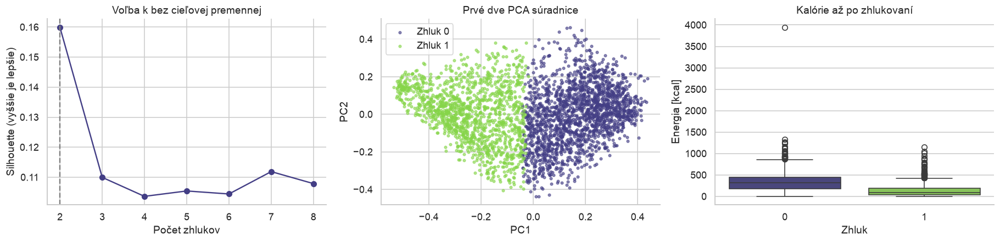

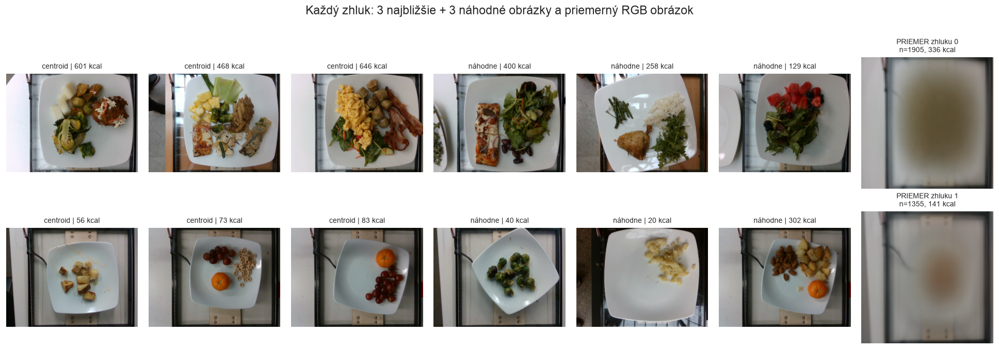

,najčastejšie ingrediencie
cluster,
0,"olive oil (1363), salt (1221), garlic (879), vinegar (667), pepper (645), onions (609), lemon juice (528), arugula (469)"
1,"olive oil (198), salt (158), almonds (127), carrot (125), cherry tomatoes (124), grapes (99), cantaloupe (92), cauliflower (86)"


In [9]:
# Táto vetva je výhradne opisná; nepoužije sa v regresných prediktoroch.
cluster_normalizer=Normalizer()
cluster_input=cluster_normalizer.fit_transform(features_df[feature_columns])
cluster_pca=PCA(n_components=50,random_state=SEED)
cluster_z=cluster_pca.fit_transform(cluster_input)
cluster_trials=[]; cluster_models={}
for k in range(2,9):
    km=KMeans(n_clusters=k,n_init=20,random_state=SEED).fit(cluster_z)
    sil=silhouette_score(cluster_z,km.labels_,sample_size=min(2000,len(df)),random_state=SEED)
    cluster_trials.append({'k':k,'silhouette':sil,'Davies_Bouldin':davies_bouldin_score(cluster_z,km.labels_),'inertia':km.inertia_})
    cluster_models[k]=km
cluster_selection=pd.DataFrame(cluster_trials)
# Výber počtu zhlukov nevidí kalórie, ingrediencie ani nutričné stĺpce.
best_k=int(cluster_selection.loc[cluster_selection.silhouette.idxmax(),'k'])
km=cluster_models[best_k]; labels=km.labels_
cluster_view=df.assign(cluster=labels)
cluster_stats=cluster_view.groupby('cluster').total_calories.agg(['count','mean','median','std','min','max'])
display(cluster_selection.round(4)); display(cluster_stats.round(2))
print('PCA zachovaná variancia:',round(float(cluster_pca.explained_variance_ratio_.sum()),3),'| počet zhlukov:',best_k)
fig,axes=plt.subplots(1,3,figsize=(16,4))
axes[0].plot(cluster_selection.k,cluster_selection.silhouette,marker='o'); axes[0].axvline(best_k,ls='--',color='grey'); axes[0].set(title='Voľba k bez cieľovej premennej',xlabel='Počet zhlukov',ylabel='Silhouette (vyššie je lepšie)')
cluster_colors = dict(enumerate(viridis_colors(best_k)))
for cluster_id, color in cluster_colors.items():
    members = labels == cluster_id
    axes[1].scatter(cluster_z[members,0], cluster_z[members,1], color=color,
                    label=f'Zhluk {cluster_id}', s=8, alpha=.6)
axes[1].set(title='Prvé dve PCA súradnice',xlabel='PC1',ylabel='PC2')
axes[1].legend()
sns.boxplot(data=cluster_view,x='cluster',y='total_calories',hue='cluster',palette=cluster_colors,legend=False,ax=axes[2]); axes[2].set(title='Kalórie až po zhlukovaní',xlabel='Zhluk',ylabel='Energia [kcal]')
plt.tight_layout(); plt.show()
# Každý zhluk: reprezentanti najbližší centroidu a náhodné príklady.
fig,axes=plt.subplots(best_k,7,figsize=(17,3*best_k),squeeze=False)
cluster_representatives={}
for cl in range(best_k):
    members=np.flatnonzero(labels==cl)
    d=np.linalg.norm(cluster_z[members]-km.cluster_centers_[cl],axis=1)
    nearest=members[np.argsort(d)[:3]]
    rest=np.setdiff1d(members,nearest)
    sampled=np.random.default_rng(SEED+cl).choice(rest,size=min(3,len(rest)),replace=False)
    cluster_representatives[cl]=np.r_[nearest,sampled]
    for j,idx in enumerate(cluster_representatives[cl]):
        with Image.open(df.at[idx,'path']) as im: axes[cl,j].imshow(im)
        axes[cl,j].set_title(f"{'centroid' if j<3 else 'náhodne'} | {y_all[idx]:.0f} kcal",fontsize=9)
    # Aritmetický priemer VŠETKÝCH RGB obrázkov zhluku v spoločnom rozlíšení.
    mean_image=rgb_small[members].astype(np.float32).mean(axis=0)/255.
    axes[cl,6].imshow(mean_image)
    axes[cl,6].set_title(f'PRIEMER zhluku {cl}\nn={len(members)}, {cluster_stats.loc[cl,"mean"]:.0f} kcal',fontsize=9)
    for ax in axes[cl]: ax.axis('off')
plt.suptitle('Každý zhluk: 3 najbližšie + 3 náhodné obrázky a priemerný RGB obrázok',y=1.01)
plt.tight_layout(); plt.show()
# Dodatočná anotácia; nebola použitá pri fitovaní KMeans ani pri výbere k.
cluster_ingredients=[]
for cl in range(best_k):
    counter=Counter(name for arr in cluster_view.loc[cluster_view.cluster==cl,'ingredients'] for name in set(x['name'] for x in arr))
    cluster_ingredients.append({'cluster':cl,'najčastejšie ingrediencie':', '.join(f'{n} ({c})' for n,c in counter.most_common(8))})
display(pd.DataFrame(cluster_ingredients).set_index('cluster'))

**Čo, prečo a ako:** L2 normalizácia porovnáva smer obrazových vektorov. PCA zníži rozmer na 50 a KMeans rozdelí iba tieto príznaky. Počet zhlukov 2–8 vyberáme podľa silhouette; vyššia hodnota znamená lepšiu vnútornú kompaktnosť a oddelenie. Davies–Bouldin má opačný smer. Nepoužívame cestu, kalórie, ingrediencie ani nutričné stĺpce pri vytváraní zhlukov.

Mriežka ukazuje **všetky** zhluky, pri každom reprezentatívne aj náhodné fotografie a priemer zo všetkých jeho obrázkov. Náhodná časť bráni interpretácii podľa samotného centroidu. Rozmazanie priemeru je prirodzený dôsledok nepresne zarovnaných jedál; jasné oblasti odhaľujú typický riad a rozloženie farieb. Kalorické štatistiky a ingrediencie pridávame až dodatočne na interpretáciu. Dvojrozmerná PCA projekcia nezobrazuje všetkých 50 dimenzií, takže vizuálne prekrývanie bodov samo osebe nevyvracia existenciu štruktúry.

**Konkrétne výsledky a pomenovanie zhlukov** sú uvedené nižšie a vychádzajú z vizuálne overeného uloženého behu. Zhluky sú vizuálne skupiny, nie automaticky kategórie jedál ani dôkaz príčinnej súvislosti s energiou.

**Namerané zhluky a ich vizuálna interpretácia:** výber skončil pri dvoch zhlukoch so silhouette 0,160. Je to najlepší výsledok zo skúšaných k, ale absolútna hodnota je pomerne nízka: ide o široké, prekrývajúce sa vizuálne skupiny. Päťdesiat PCA komponentov zachovalo 81,5 % variability normalizovaných príznakov.

**Zhluk 0 – zložitejšie a vizuálne plnšie taniere:** 1 905 fotografií, priemer 336,13 kcal a medián 313,44 kcal. V reprezentantoch vidno kombinácie príloh, zeleniny, mäsa či vajec; jedlo vypĺňa väčšiu plochu záberu. Náhodné príklady zahŕňajú aj ľahšie šaláty a ovocie, preto nejde o čistú kategóriu mäsa ani o synonymum vysokých kalórií. Priemerný obrázok má širokú hnedo-zelenú stredovú oblasť jedla. Medzi najčastejšie anotované ingrediencie patria olivový olej, soľ a cesnak; olej sa objavuje na 1 363 z 1 905 fotografií tohto zhluku.

**Zhluk 1 – jednoduchšie jedlá, menšie porcie a viac viditeľného pozadia:** 1 355 fotografií, priemer 141,35 kcal a medián 91,24 kcal. Pri centroidoch sú malé porcie zemiakov, ovocie a jednoduché kombinácie; náhodné ukážky zahŕňajú ružičkový kel, vajcia aj orechy. Orechy pripomínajú, že malá viditeľná porcia môže byť energeticky hustá. Priemerný obrázok ukazuje viac prázdneho riadu a výraznejšiu spoločnú konštrukciu snímacieho zariadenia; stredná farebná škvrna jedla je menšia. Olivový olej je anotovaný len na 198 z 1 355 fotografií.

**Čo rozdiel znamená:** priemerná energia zhluku 0 je o približne 194,8 kcal vyššia, ale rozsahy kalórií sa prekrývajú. Väčšie viditeľné pokrytie taniera a zložitejšie kombinácie sú s vyššou energiou zlučiteľné. Zároveň sa líši rámovanie snímky a množstvo pozadia. Extraktor teda zoskupuje aj vlastnosti fotografovania a riadu, nielen samotné ingrediencie; nemožno z toho odvodiť kalorickú hodnotu podľa zhluku ani príčinný vzťah. Táto slabina je dôvodom zobrazenia priemerov a náhodných príkladov popri centroidoch.

## 6. Regresory nad ImageNet príznakmi: MLP, SVR a ensemble

MLP epocha 20 | val MAE 69.17


MLP epocha 40 | val MAE 67.04


MLP epocha 60 | val MAE 67.72


MLP epocha 80 | val MAE 69.13


,MSE,MAE,RMSE,R2
model,,,,
MLP,12566.439,66.245,112.100,0.719
SVR C=1,10725.621,67.134,103.565,0.760
SVR C=10,10206.756,68.242,101.028,0.771
ExtraTrees leaf=2,13649.099,77.906,116.829,0.694
ExtraTrees leaf=5,13952.789,78.208,118.122,0.688
SVR C=100,16163.239,79.323,127.135,0.638
SVR C=1000,16163.239,79.323,127.135,0.638
ExtraTrees leaf=10,14630.239,80.366,120.956,0.672


Víťaz podľa MAE medzi modelmi zlepšujúcimi aj validačné RMSE CNN: SVR C=1


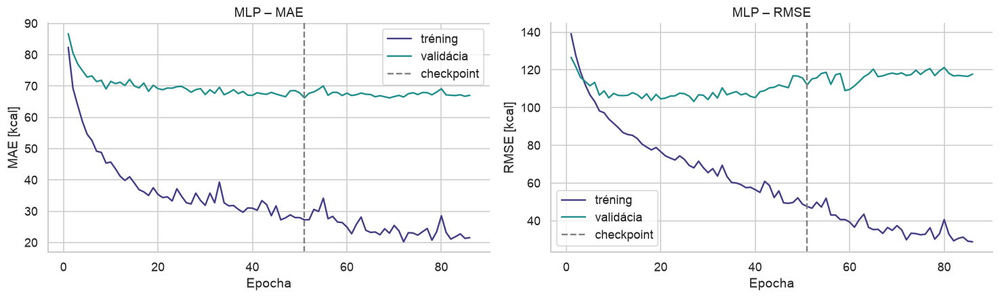

['/Users/samuelbagin/Desktop/prac-plocha/school/SUNS/zadania/03/.suns3/transfer.joblib']

In [10]:
# Nezávislá regresná vetva: scaler sa učí len na tréningu a NEPOUŽÍVA cluster_pca.
feature_scaler=StandardScaler().fit(image_features[SPLITS['train']])
scaled_features=feature_scaler.transform(image_features).astype(np.float32)
feature_tensor=torch.from_numpy(scaled_features)
class FeatureMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(576,128),nn.LayerNorm(128),nn.ReLU(),nn.Dropout(.35),
                               nn.Linear(128,32),nn.ReLU(),nn.Dropout(.15),nn.Linear(32,1))
    def forward(self,x): return self.net(x).squeeze(-1)

def feature_loader(split,shuffle=False,epoch=0):
    idx=SPLITS[split]
    return DataLoader(TensorDataset(feature_tensor[idx],torch.tensor((y_all[idx]-y_mean)/y_std),torch.tensor(idx)),
                      batch_size=64,shuffle=shuffle,generator=torch.Generator().manual_seed(SEED+epoch),num_workers=0)

seed_all(); mlp=FeatureMLP().to(DEVICE)
optimizer=torch.optim.AdamW(mlp.parameters(),lr=5e-4,weight_decay=1e-2)
scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,factor=.5,patience=10)
mlp_history=[]; best_val=np.inf; stale=0; mlp_best_state=None
for epoch in range(250):
    seed_all(SEED+epoch); mlp.train()
    for x,y,_ in feature_loader('train',shuffle=True,epoch=epoch):
        optimizer.zero_grad(set_to_none=True); p=mlp(x.to(DEVICE))
        loss=nn.functional.mse_loss(p,y.to(DEVICE)); loss.backward()
        nn.utils.clip_grad_norm_(mlp.parameters(),5.); optimizer.step()
    yt,pt,_=predict_torch(mlp,feature_loader('train'))
    yv,pv,_=predict_torch(mlp,feature_loader('val'))
    mt,mv=metrics(yt,pt),metrics(yv,pv); scheduler.step(mv['MAE'])
    mlp_history.append({'epoch':epoch+1,'train_MAE':mt['MAE'],'val_MAE':mv['MAE'],
                        'train_RMSE':mt['RMSE'],'val_RMSE':mv['RMSE']})
    if mv['MAE']<best_val-.05:
        best_val=mv['MAE']; mlp_best_state=cpu_state(mlp); mlp_best_epoch=epoch+1; stale=0
    else: stale+=1
    if (epoch+1)%20==0: print('MLP epocha',epoch+1,'| val MAE',round(mv['MAE'],2),flush=True)
    if stale>=35: break
mlp.load_state_dict(mlp_best_state)
transfer_models={}; transfer_validation=[]
for c in [1.,10.,100.,1000.]:
    name=f'SVR C={c:g}'
    model=make_pipeline(StandardScaler(),SVR(C=c,epsilon=.1,kernel='rbf',gamma='scale'))
    model.fit(image_features[SPLITS['train']],(y_all[SPLITS['train']]-y_mean)/y_std)
    pv=model.predict(image_features[SPLITS['val']])*y_std+y_mean
    transfer_models[name]=model
    transfer_validation.append({'model':name,**metrics(y_all[SPLITS['val']],pv)})
for leaf in [2,5,10]:
    name=f'ExtraTrees leaf={leaf}'
    model=ExtraTreesRegressor(n_estimators=400,min_samples_leaf=leaf,max_features=.7,n_jobs=4,random_state=SEED)
    model.fit(image_features[SPLITS['train']],y_all[SPLITS['train']])
    pv=model.predict(image_features[SPLITS['val']])
    transfer_models[name]=model
    transfer_validation.append({'model':name,**metrics(y_all[SPLITS['val']],pv)})
transfer_validation.append({'model':'MLP',**metrics(y_all[SPLITS['val']],predict_torch(mlp,feature_loader('val'))[1])})
transfer_validation=pd.DataFrame(transfer_validation).set_index('model').sort_values('MAE')
cnn_val_y,cnn_val_p,_=predict_torch(best_cnn.to(DEVICE),image_loader('val'))
cnn_val_reference=metrics(cnn_val_y,cnn_val_p)
transfer_eligible=transfer_validation[(transfer_validation.MAE<cnn_val_reference['MAE']) &
                                      (transfer_validation.RMSE<cnn_val_reference['RMSE'])]
assert not transfer_eligible.empty, 'Žiadny transfer regresor vo validácii nezlepšil MAE aj RMSE CNN.'
best_transfer_name=transfer_eligible.index[0]
display(transfer_validation.round(3)); print('Víťaz podľa MAE medzi modelmi zlepšujúcimi aj validačné RMSE CNN:',best_transfer_name)
h=pd.DataFrame(mlp_history)
fig,ax=plt.subplots(1,2,figsize=(13,4))
for j,m in enumerate(['MAE','RMSE']):
    ax[j].plot(h.epoch,h[f'train_{m}'],label='tréning',color=SPLIT_COLORS['train']); ax[j].plot(h.epoch,h[f'val_{m}'],label='validácia',color=SPLIT_COLORS['val'])
    ax[j].axvline(mlp_best_epoch,color='grey',ls='--',label='checkpoint')
    ax[j].set(xlabel='Epocha',ylabel=f'{m} [kcal]',title=f'MLP – {m}'); ax[j].legend()
plt.tight_layout();plt.show()
joblib.dump({'split_key':SPLIT_KEY,'scaler':feature_scaler,'models':transfer_models,
             'validation':transfer_validation,'mlp_state':mlp_best_state,'mlp_history':mlp_history,
             'best_name':best_transfer_name,'y_mean':y_mean,'y_std':y_std},ART/'transfer.joblib',compress=3)

**Čo, prečo a ako:** MLP sa učí nelineárnu kombináciu 576 príznakov a má uloženú tréningovú aj validačnú krivku. Dropout, LayerNorm, weight decay a skoré zastavenie obmedzujú pretrénovanie. SVR skúša štyri sily penalizácie chyby pri rovnakom RBF jadre. Ensemble ExtraTrees porovnáva tri minimálne veľkosti listu. Hyperparametre posudzujeme iba na validácii. Pri výbere finálneho transferového regresora požadujeme zlepšenie MAE aj RMSE vlastnej CNN a potom minimalizujeme MAE. Predídeme tak výberu modelu, ktorý síce znižuje typickú chybu, ale zhoršuje veľké omyly.

MLP a SVR používajú škálovanie vstupov naučené iba na tréningu. MLP aj SVR predikujú štandardizované kalórie, ktoré sa vrátia do kcal; stromy pracujú priamo v kcal. Stromy ani SVR nemajú epochové učenie, preto pre ne nemožno zmysluplne nakresliť rovnaký typ tréningovej krivky. Pri MLP je povinná krivka zobrazená aj v prípade, že validačne vyhrá iný regresor.

**Výsledok:** tabuľka vyššie obsahuje validačné metriky, nie testové. Výsledný model prenosu je uzamknutý pred otvorením testu. MLP síce dosiahla najnižšie validačné MAE, ale jej validačné RMSE je horšie než pri CNN; rozdiel train/val navyše ukazuje pretrénovanie. Preto finálna voľba môže uprednostniť SVR, aj keď je MLP v tabuľke MAE prvá. ImageNet backbone zostáva celý čas zamrazený; učí sa iba regresor.

**Nameraný výsledok:** najnižšie validačné MAE spomedzi modelov, ktoré zároveň zlepšili validačné RMSE CNN, dosiahol **SVR C=1**, a to 67.13 kcal. MLP dosiahla 66.24 kcal. Výber teda vyplynul z validácie a nebol vopred pridelený neurónovej sieti. Testové porovnanie s CNN je uvedené v časti 8.

## 7. Malý Vision Transformer na RGB obrázkoch - BONUS

TinyViT | epocha  45 | train MAE 84.7 | val MAE 95.9 kcal | 6 s


TinyViT | epocha  50 | train MAE 84.2 | val MAE 94.9 kcal | 18 s


TinyViT | epocha  55 | train MAE 82.1 | val MAE 93.9 kcal | 30 s


TinyViT | epocha  60 | train MAE 82.4 | val MAE 94.8 kcal | 46 s


TinyViT | epocha  65 | train MAE 82.0 | val MAE 93.9 kcal | 59 s


TinyViT | epocha  70 | train MAE 80.4 | val MAE 92.4 kcal | 70 s


... (3 outputs left out)

TinyViT | epocha  90 | train MAE 78.9 | val MAE 92.7 kcal | 127 s


TinyViT | epocha  95 | train MAE 78.4 | val MAE 92.3 kcal | 141 s


TinyViT | najlepšia epocha: 74 | val MAE: 91.27


Počet parametrov TinyViT: 152257


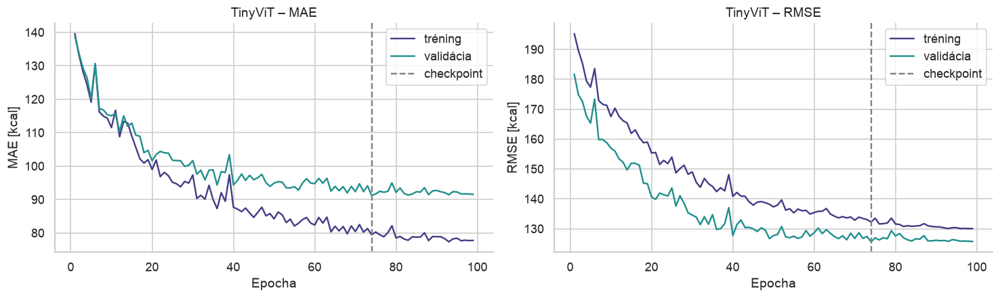

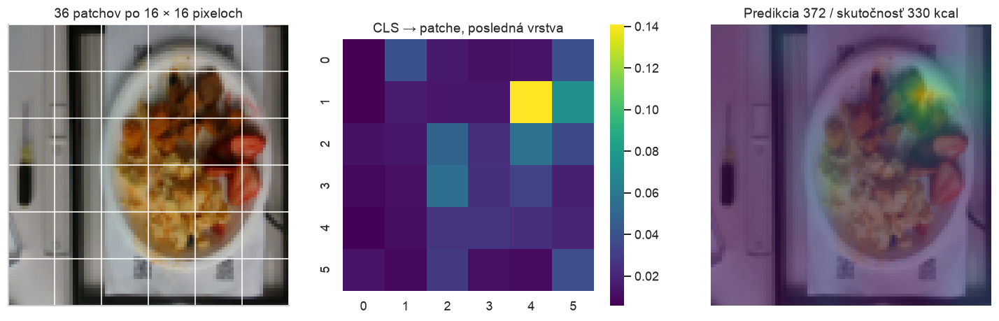

In [11]:
class TransformerBlock(nn.Module):
    def __init__(self,dim=64,heads=4,dropout=.2):
        super().__init__()
        self.norm1=nn.LayerNorm(dim); self.norm2=nn.LayerNorm(dim)
        self.attn=nn.MultiheadAttention(dim,heads,dropout=dropout,batch_first=True)
        self.mlp=nn.Sequential(nn.Linear(dim,dim*2),nn.GELU(),nn.Dropout(dropout),nn.Linear(dim*2,dim),nn.Dropout(dropout))
    def forward(self,x,return_attention=False):
        q=self.norm1(x)
        attended,weights=self.attn(q,q,q,need_weights=return_attention,average_attn_weights=False)
        x=x+attended; x=x+self.mlp(self.norm2(x))
        return (x,weights) if return_attention else x
class TinyViT(nn.Module):
    def __init__(self):
        super().__init__()
        self.patch_size=16; dim=64
        self.patch=nn.Conv2d(3,dim,kernel_size=16,stride=16)
        self.cls=nn.Parameter(torch.zeros(1,1,dim))
        self.pos=nn.Parameter(torch.randn(1,37,dim)*.02)
        self.blocks=nn.ModuleList([TransformerBlock(dim) for _ in range(3)])
        self.norm=nn.LayerNorm(dim); self.head=nn.Sequential(nn.Dropout(.2),nn.Linear(dim,1))
    def forward(self,x,return_attention=False):
        x=self.patch(x).flatten(2).transpose(1,2)
        x=torch.cat([self.cls.expand(x.size(0),-1,-1),x],dim=1)+self.pos
        attentions=[]
        for block in self.blocks:
            if return_attention:
                x,a=block(x,True); attentions.append(a)
            else: x=block(x)
        prediction=self.head(self.norm(x[:,0])).squeeze(-1)
        return (prediction,attentions) if return_attention else prediction
vit_config=dict(name='TinyViT',lr=3e-4,weight_decay=.02,augment=True,architecture='96-p16-d64-h4-l3-v1')
vit,vit_run=fit_image_model('TinyViT',TinyViT,vit_config,max_epochs=120,patience=25)
print('Počet parametrov TinyViT:',sum(p.numel() for p in vit.parameters()))
h=pd.DataFrame(vit_run['history'])
fig,ax=plt.subplots(1,2,figsize=(13,4))
for j,m in enumerate(['MAE','RMSE']):
    ax[j].plot(h.epoch,h[f'train_{m}'],label='tréning',color=SPLIT_COLORS['train']);ax[j].plot(h.epoch,h[f'val_{m}'],label='validácia',color=SPLIT_COLORS['val'])
    ax[j].axvline(vit_run['best_epoch'],color='grey',ls='--',label='checkpoint')
    ax[j].set(xlabel='Epocha',ylabel=f'{m} [kcal]',title=f'TinyViT – {m}');ax[j].legend()
plt.tight_layout();plt.show()
# Pozornosť ukážeme na validačnom príklade, nezávisle od testových výsledkov.
x,y,idx=next(iter(image_loader('val')))
vit.eval()
with torch.inference_mode():
    p,attn=vit(x[:1].to(DEVICE),return_attention=True)
last_attention=attn[-1][0].mean(0)[0,1:].cpu().numpy().reshape(6,6)
fig,ax=plt.subplots(1,3,figsize=(13,4))
ax[0].imshow(rgb_small[int(idx[0])]); ax[0].set_title('36 patchov po 16 × 16 pixeloch')
ax[0].set_xticks(np.arange(-.5,96,16)); ax[0].set_yticks(np.arange(-.5,96,16)); ax[0].grid(color='white'); ax[0].tick_params(labelbottom=False,labelleft=False)
sns.heatmap(last_attention,cmap='viridis',square=True,ax=ax[1]);ax[1].set_title('CLS → patche, posledná vrstva')
ax[2].imshow(rgb_small[int(idx[0])]);ax[2].imshow(last_attention,extent=(-.5,95.5,95.5,-.5),cmap='viridis',alpha=.5,interpolation='bilinear');ax[2].axis('off');ax[2].set_title(f"Predikcia {p.item()*y_std+y_mean:.0f} / skutočnosť {y_all[int(idx[0])]:.0f} kcal")
plt.tight_layout();plt.show()

**Čo, prečo a ako:** obrázok 96 × 96 rozdelíme na 36 farebných patchov 16 × 16. Konvolúcia so zhodným krokom tu implementuje iba lineárnu projekciu každého patchu do 64 čísel. Pridáme naučené pozície a token CLS. Tri transformerové bloky so štyrmi hlavami self-attention umožnia každej časti snímky porovnať sa s ostatnými. Reziduálne spojenia a LayerNorm stabilizujú tréning; hlava z CLS predikuje kalórie.

Na rozdiel od transfer learningu tento ViT nemá predtrénované váhy a trénuje priamo z RGB obrázkov. Používa ten istý split, normalizáciu cieľa, augmentáciu a validačný výber. ViT má limit 120 epoch a trpezlivosť skorého zastavenia 25 epoch. CNN majú základný limit 90 epoch a validačný víťaz môže pokračovať do 150. Porovnanie preto nie je izolovaným testom samotnej architektúry pri rovnakom výpočtovom rozpočte.

**Interpretácia obrázka:** mapa je priemer attention hláv poslednej vrstvy z CLS na jednotlivé patche. Ukazuje rozdelenie pozornosti, nie dokázanú príčinu predikcie ani spoľahlivú segmentáciu jedla. Transformer na malom datasete nemusí prekonať ImageNet prenos; nepovinná úloha vyžaduje zmysluplne natrénovanú transformerovú regresiu, nie vopred predpokladané víťazstvo.

Zdroj princípu: [Dosovitskiy a kol., An Image is Worth 16×16 Words](https://arxiv.org/abs/2010.11929).

**Nameraný výsledok:** ViT použil checkpoint z epochy 74 po 99 vykonaných epochách. Tréningové MAE je 79.49 kcal a validačné 91.27 kcal. Tento výsledok vznikol učením z obrázkov bez predtrénovaných váh.

**Konkrétna mapa pozornosti:** na zvolenej validačnej fotografii je najsilnejšia posledná CLS pozornosť v hornej pravej oblasti jedla. Odhad je približne 372 kcal pri skutočnosti 330 kcal. Nie všetky patche majú rovnakú váhu, ale jedna mapa neoveruje spoľahlivosť vysvetlenia pre celý dataset. Model má 152 257 parametrov.

**Princíp attention:** $Q=XW_Q$, $K=XW_K$, $V=XW_V$ a $\operatorname{Attention}(Q,K,V)=\operatorname{softmax}(QK^\top/\sqrt{d_k})V$. Naučené porovnanie query a key rozhoduje, ako silno sa do každého tokenu primiešajú informácie z ostatných tokenov. Viac hláv môže súčasne modelovať rôzne vzťahy; ich význam však nie je vopred pomenovaný.

V attention vzorci je $d_k=16$ rozmer jednej zo štyroch hláv; spoločne pracujú so 64-rozmerným tokenom.

## 8. Uzamknuté modely: tréningové a testové metriky v kcal

MSE                MAE             RMSE  \
split                          test      train    test   train     test   
model                                                                     
C1 základ                 11773.714  13471.905  76.930  65.692  108.507   
C2 nižší krok             13362.021  16829.734  82.136  76.258  115.594   
C3 silnejší dropout       12601.410  15615.690  79.940  72.593  112.256   
C4 väčšia kapacita        12174.109  15669.484  77.894  72.055  110.336   
C5 silnejší weight decay  11839.854  14133.797  76.470  67.218  108.811   
C6 robustná Huber         11985.030  15549.575  74.328  67.319  109.476   

                                      R2         
split                       train   test  train  
model                                            
C1 základ                 116.069  0.725  0.731  
C2 nižší krok             129.729  0.688  0.664  
C3 silnejší dropout       124.963  0.705  0.688  
C4 väčšia kapacita        125.178  0.715  0.687  
C5 silnejší weight decay  118.886  0.723  0.717  
C6 robustná Huber         124.698  0.720  0.689

MSE                 MAE              RMSE           \
split                  test      train     test    train     test    train   
model                                                                        
C1 základ         11773.714  13471.905   76.930   65.692  108.507  116.069   
MLP                7443.360   2266.942   59.951   27.268   86.275   47.612   
Priemer tréningu  42781.573  50016.202  165.648  169.276  206.837  223.643   
SVR C=1            7654.764   9330.501   61.181   33.338   87.492   96.595   
TinyViT           15629.933  17491.439   87.309   79.489  125.020  132.255   

                     R2         
split              test  train  
model                           
C1 základ         0.725  0.731  
MLP               0.826  0.955  
Priemer tréningu -0.000 -0.000  
SVR C=1           0.821  0.813  
TinyViT           0.635  0.650

MSE      MAE     RMSE     R2
model                    split                                    
C1 základ                train  13471.905   65.692  116.069  0.731
                         test   11773.714   76.930  108.507  0.725
C2 nižší krok            train  16829.734   76.258  129.729  0.664
                         test   13362.021   82.136  115.594  0.688
C3 silnejší dropout      train  15615.690   72.593  124.963  0.688
                         test   12601.410   79.940  112.256  0.705
C4 väčšia kapacita       train  15669.484   72.055  125.178  0.687
                         test   12174.109   77.894  110.336  0.715
C5 silnejší weight decay train  14133.797   67.218  118.886  0.717
                         test   11839.854   76.470  108.811  0.723
C6 robustná Huber        train  15549.575   67.319  124.698  0.689
                         test   11985.030   74.328  109.476  0.720
SVR C=1                  train   9330.501   33.338   96.595  0.813
                         test    7654.764   61.181   87.492  0.821
SVR C=10                 train   4752.267   20.688   68.937  0.905
                         test    6617.616   58.934   81.349  0.845
SVR C=100                train    420.875   19.693   20.515  0.992
                         test    8217.260   66.814   90.649  0.808
SVR C=1000               train    420.875   19.693   20.515  0.992
                         test    8217.260   66.814   90.649  0.808
ExtraTrees leaf=2        train   1641.577    5.503   40.516  0.967
                         test   10735.274   72.307  103.611  0.749
ExtraTrees leaf=5        train   5285.054   24.979   72.698  0.894
                         test   11037.715   72.919  105.061  0.742
ExtraTrees leaf=10       train   9567.449   48.388   97.813  0.809
                         test   11644.932   75.121  107.912  0.728
MLP                      train   2266.942   27.268   47.612  0.955
                         test    7443.360   59.951   86.275  0.826
TinyViT                  train  17491.439   79.489  132.255  0.650
                         test   15629.933   87.309  125.020  0.635
Priemer tréningu         train  50016.202  169.276  223.643 -0.000
                         test   42781.573  165.648  206.837 -0.000

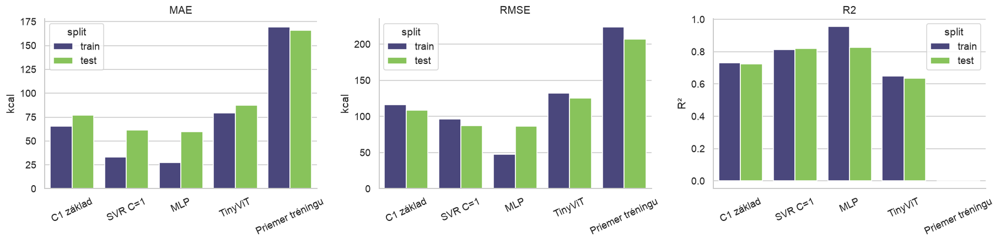

,CNN,Transfer
MAE,76.930,61.181
RMSE,108.507,87.492
R2,0.725,0.821


Transfer zlepšil testové MAE: True
Transfer zlepšil testové RMSE: True
Transfer zlepšil testové R²: True


In [12]:
# Až teraz používame test na vyhodnotenie. Ďalší výber hyperparametrov podľa testu nerobíme.
all_predictions={}; metric_rows=[]
for name,model in cnn_models.items():
    model.to(DEVICE)
    for split in ['train','val','test']:
        y,p,ids=predict_torch(model,image_loader(split))
        assert np.array_equal(ids,SPLITS[split]); assert np.allclose(y,y_all[ids],atol=.001)
        all_predictions[(name,split)]=p
        metric_rows.append({'model':name,'split':split,**metrics(y,p)})
    model.to('cpu')
for name in [*transfer_models,'MLP','TinyViT','Priemer tréningu']:
    for split in ['train','val','test']:
        ids=SPLITS[split]
        if name=='MLP': p=predict_torch(mlp,feature_loader(split))[1]
        elif name=='TinyViT': p=predict_torch(vit,image_loader(split))[1]
        elif name=='Priemer tréningu': p=np.full(len(ids),y_mean)
        else:
            p=transfer_models[name].predict(image_features[ids])
            if name.startswith('SVR'):p=p*y_std+y_mean
        all_predictions[(name,split)]=p
        metric_rows.append({'model':name,'split':split,**metrics(y_all[ids],p)})
all_metrics=pd.DataFrame(metric_rows)
cnn_table=all_metrics[all_metrics.model.isin(cnn_models)&all_metrics.split.isin(['train','test'])].pivot(index='model',columns='split',values=['MSE','MAE','RMSE','R2'])
display(cnn_table.round(3))
comparison_names=['Priemer tréningu',best_cnn_name,best_transfer_name,'MLP','TinyViT']
comparison_names=list(dict.fromkeys(comparison_names))
comparison=all_metrics[all_metrics.model.isin(comparison_names)&all_metrics.split.isin(['train','test'])]
display(comparison.pivot(index='model',columns='split',values=['MSE','MAE','RMSE','R2']).round(3))
# Úplná tabuľka všetkých skúšaných modelov, aby sa nestratil ani nevíťazný regresor.
display(all_metrics[all_metrics.split.isin(['train','test'])].set_index(['model','split']).round(3))
fig,axes=plt.subplots(1,3,figsize=(16,4))
for ax,metric in zip(axes,['MAE','RMSE','R2']):
    sns.barplot(data=comparison,x='model',y=metric,hue='split',palette=SPLIT_COLORS,ax=ax)
    ax.set_title(metric);ax.set_xlabel('');ax.tick_params(axis='x',rotation=25)
    ax.set_ylabel('kcal' if metric!='R2' else 'R²')
plt.tight_layout();plt.show()
# Podmienená kontrola požadovaného zlepšenia; úspech netvrdíme bez nameraných metrík.
cnn_test=all_metrics.query('model == @best_cnn_name and split == "test"').iloc[0]
transfer_test=all_metrics.query('model == @best_transfer_name and split == "test"').iloc[0]
improvement=pd.DataFrame({'CNN':[cnn_test.MAE,cnn_test.RMSE,cnn_test.R2],
                          'Transfer':[transfer_test.MAE,transfer_test.RMSE,transfer_test.R2]},index=['MAE','RMSE','R2'])
display(improvement.round(3))
print('Transfer zlepšil testové MAE:',bool(transfer_test.MAE<cnn_test.MAE))
print('Transfer zlepšil testové RMSE:',bool(transfer_test.RMSE<cnn_test.RMSE))
print('Transfer zlepšil testové R²:',bool(transfer_test.R2>cnn_test.R2))

**Čo, prečo a ako:** prvá spoločná tabuľka obsahuje všetkých šesť CNN konfigurácií, každú s MSE, MAE, RMSE a R² na tréningu aj teste. Ďalšie tabuľky porovnávajú baseline, vybrané modely a všetky regresory. MSE má jednotku kcal², MAE a RMSE kcal, R² je bezrozmerné a môže byť záporné. Vyššie R² a nižšie ostatné metriky sú lepšie.

Konštantný baseline predikuje iba tréningový priemer. Každý model používa ten istý test a pôvodné kalorické hodnoty bez orezania extrémov. Modely nepreberajú testový priemer, škálovanie ani zhlukové štítky. Prípadné záporné predikcie by metriky zohľadnili bez skrytého orezania na nulu.

**Interpretácia:** požadované zlepšenie transfer learningu posudzujeme na meraní, nie podľa názvu modelu. Podrobný slovný záver s konkrétnymi číslami je v poslednej časti. Testové metriky všetkých konfigurácií uvádzame na splnenie zadania, ale na ich základe nemeníme už vybraného víťaza.

**Nameraný výsledok:** vybraná CNN má na teste MAE 76.93 kcal, RMSE 108.51 kcal a R² 0.725. Transfer má MAE 61.18 kcal, RMSE 87.49 kcal a R² 0.821. Zlepšil teda všetky štyri požadované metriky; MSE a RMSE vyjadrujú rovnakú kvadratickú chybu v odlišnej mierke. MAE sa znížilo o 20.5 %. Konštantný baseline má MAE 165.65 kcal. ViT dosiahol MAE 87.31 kcal a R² 0.635.

**Prečo po teste nemeníme výber:** MLP má na tomto teste dokonca mierne lepšie MAE (59.95 kcal) než zvolený SVR (61.18 kcal). Na validácii však zhoršovala RMSE CNN a ukazovala výraznejšie pretrénovanie, preto nesplnila zvolené výberové pravidlo. Tento dodatočný testový výsledok férovo uvádzame, ale nepoužívame ho na nový výber modelu.

**Definície metrík:** pre $n$ snímok a reziduál $r_i=y_i-\hat y_i$ platí

$$\mathrm{MAE}=\frac1n\sum_{i=1}^n|r_i|,\qquad
\mathrm{MSE}=\frac1n\sum_{i=1}^n r_i^2,\qquad
\mathrm{RMSE}=\sqrt{\mathrm{MSE}}.$$

$$R^2=1-\frac{\sum_i r_i^2}{\sum_i(y_i-\bar y)^2}.$$

Pri $R^2$ je $\bar y$ priemer práve hodnotenej množiny a slúži iba na definíciu metriky. Nepoužíva sa ako parameter prediktora. MAE opisuje typickú absolútnu chybu, zatiaľ čo RMSE silnejšie zvýrazní veľké omyly.

## 9. Diagnostika predikcií, reziduálov a najväčších chýb

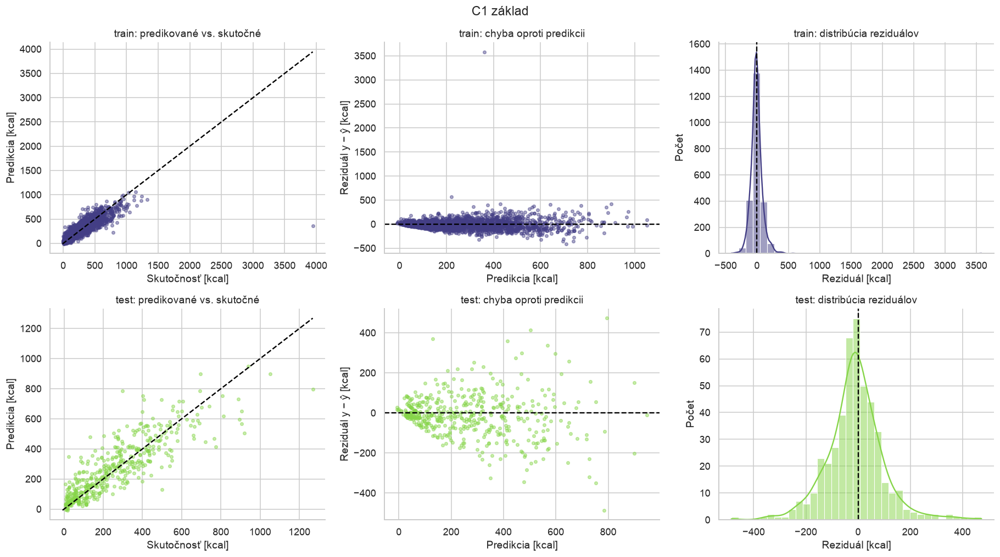

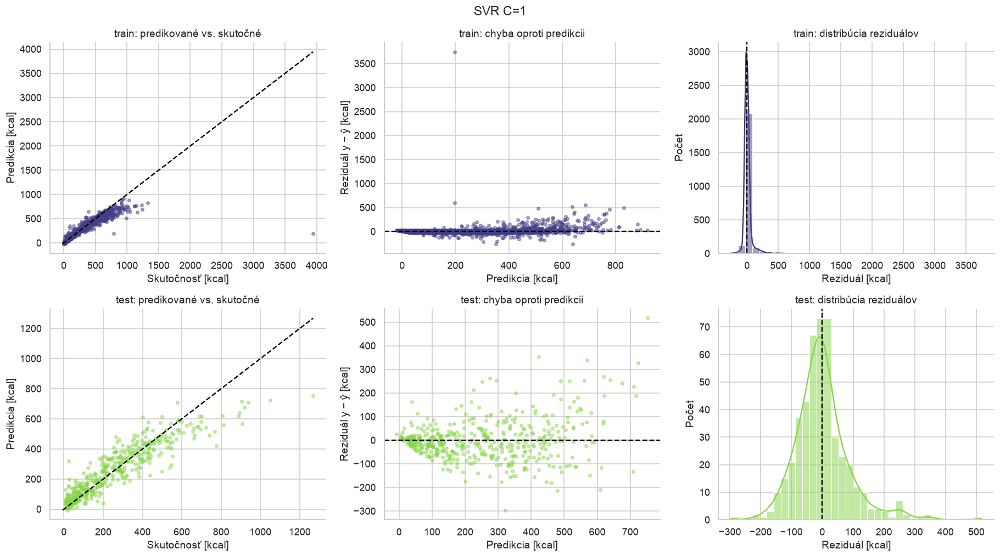

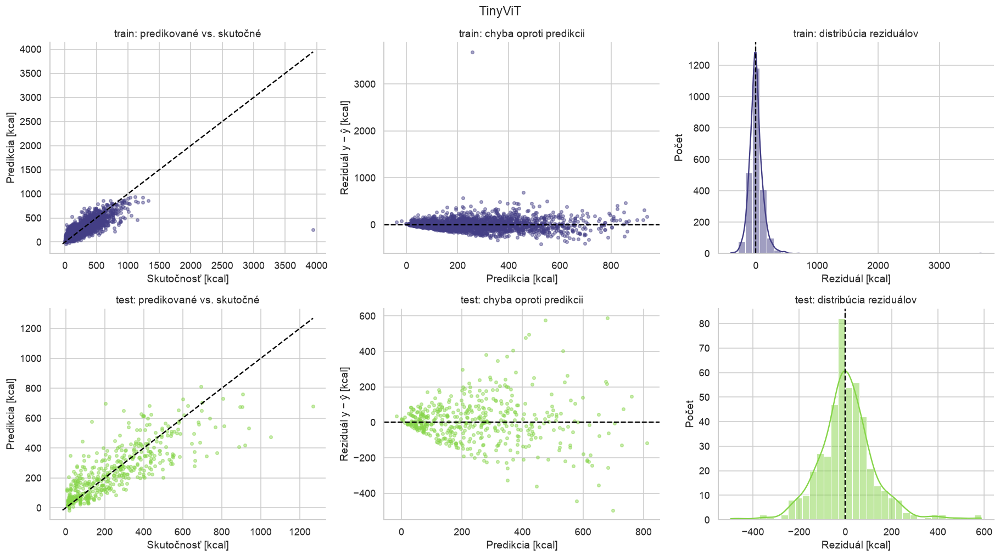

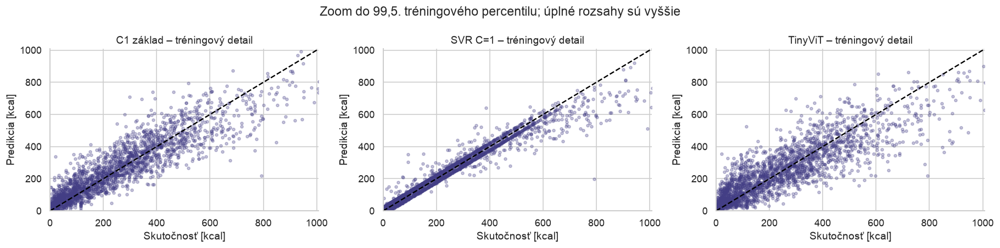

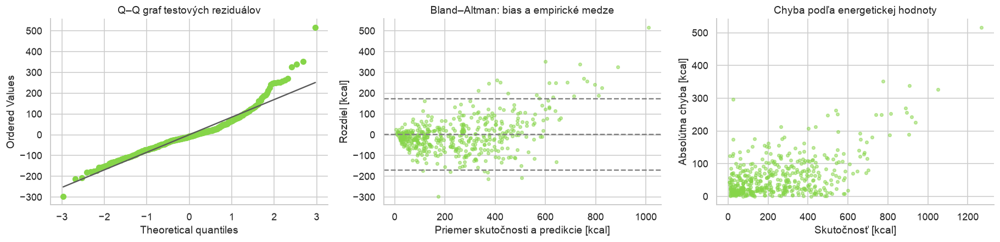

,model,pásmo,n,MAE,RMSE,bias y−ŷ
0,C1 základ,nízke,121,45.27,67.18,-37.52
1,C1 základ,stredné,223,74.38,100.72,-28.00
2,C1 základ,vysoké,122,112.99,148.16,42.64
3,SVR C=1,nízke,121,37.09,54.93,-30.06
4,SVR C=1,stredné,223,53.34,68.16,-21.92
5,SVR C=1,vysoké,122,99.41,133.25,70.48
6,TinyViT,nízke,121,57.92,82.40,-50.21
7,TinyViT,stredné,223,73.70,101.99,-11.31
8,TinyViT,vysoké,122,141.33,184.26,93.14


Tréningové hranice pásiem: 81.15 a 372.09 kcal


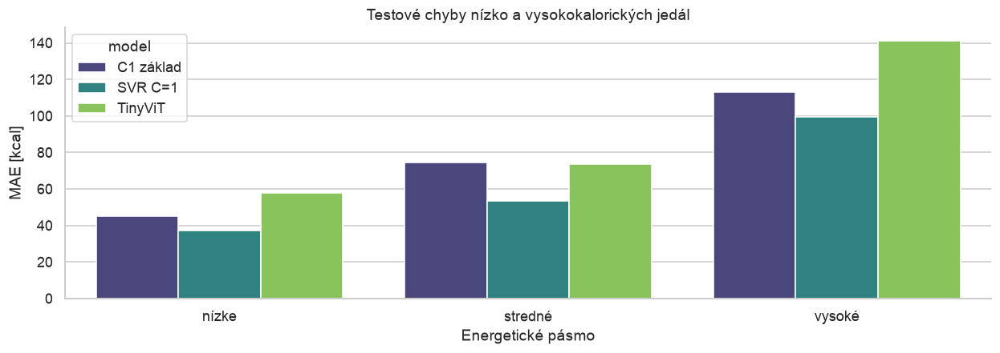

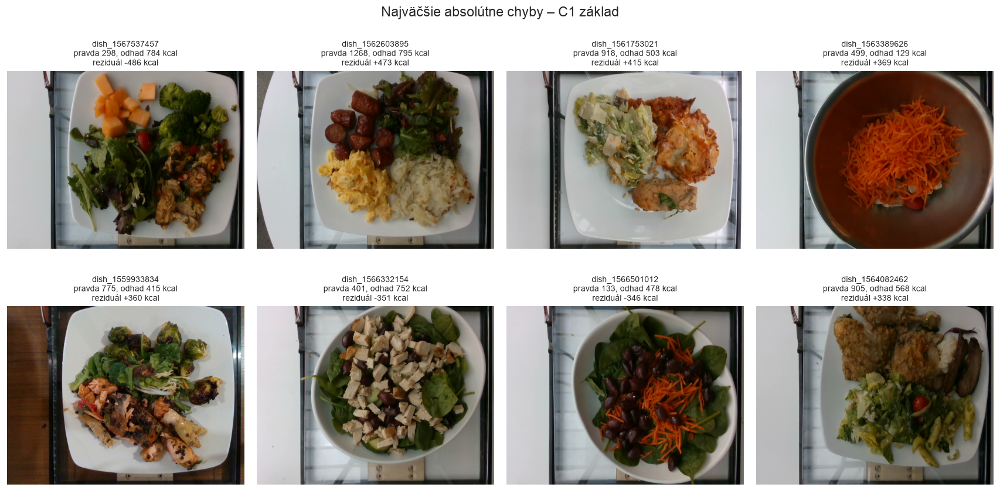

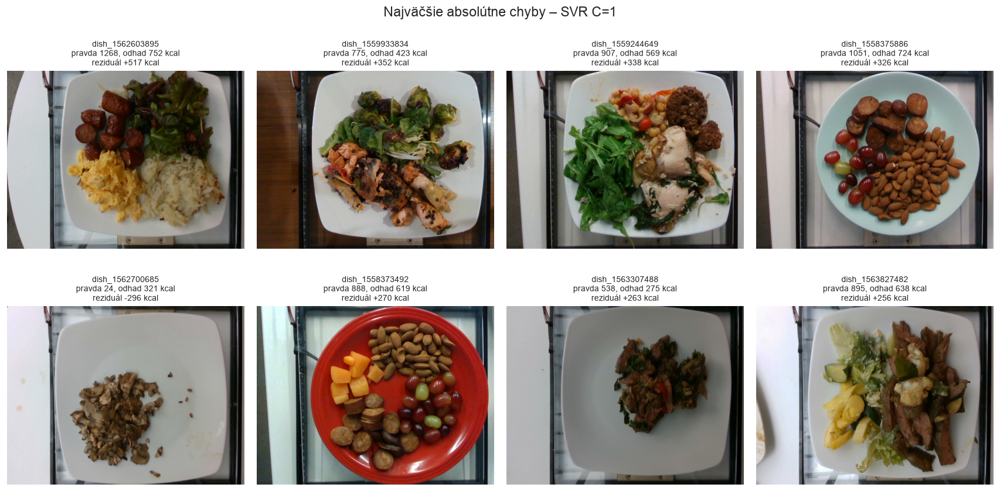

Rozdiel MAE transfer − CNN: -15.75 kcal
95 % skupinový bootstrap interval: [-21.75  -9.86] kcal


['/Users/samuelbagin/Desktop/prac-plocha/school/SUNS/zadania/03/.suns3/results.joblib']

In [5]:
def diagnostic_plots(name):
    fig,axes=plt.subplots(2,3,figsize=(16,9))
    for j,split in enumerate(['train','test']):
        y=y_all[SPLITS[split]];p=all_predictions[(name,split)]; residual=y-p
        axes[j,0].scatter(y,p,s=12,alpha=.45,color=SPLIT_COLORS[split])
        lim=[min(0,float(p.min())),max(float(y.max()),float(p.max()))]
        axes[j,0].plot(lim,lim,'k--');axes[j,0].set(xlabel='Skutočnosť [kcal]',ylabel='Predikcia [kcal]',title=f'{split}: predikované vs. skutočné')
        axes[j,1].scatter(p,residual,s=12,alpha=.45,color=SPLIT_COLORS[split]);axes[j,1].axhline(0,color='black',ls='--')
        axes[j,1].set(xlabel='Predikcia [kcal]',ylabel='Reziduál y − ŷ [kcal]',title=f'{split}: chyba oproti predikcii')
        sns.histplot(residual,bins=35,kde=True,color=SPLIT_COLORS[split],ax=axes[j,2]);axes[j,2].axvline(0,color='black',ls='--')
        axes[j,2].set(xlabel='Reziduál [kcal]',ylabel='Počet',title=f'{split}: distribúcia reziduálov')
    plt.suptitle(name);plt.tight_layout();plt.show()
for name in dict.fromkeys([best_cnn_name,best_transfer_name,'TinyViT']): diagnostic_plots(name)

# Detail bežného rozsahu dopĺňa úplné grafy; nemení dáta ani výpočet metrík.
fig,zoom_axes=plt.subplots(1,3,figsize=(16,4))
zoom_limit=float(np.quantile(y_all[SPLITS['train']],.995))
for ax,name in zip(zoom_axes,[best_cnn_name,best_transfer_name,'TinyViT']):
    yy=y_all[SPLITS['train']];pp=all_predictions[(name,'train')]
    ax.scatter(yy,pp,s=10,alpha=.3);ax.plot([0,zoom_limit],[0,zoom_limit],'k--')
    ax.set(xlim=(0,zoom_limit),ylim=(0,zoom_limit),xlabel='Skutočnosť [kcal]',
           ylabel='Predikcia [kcal]',title=name+' – tréningový detail')
plt.suptitle('Zoom do 99,5. tréningového percentilu; úplné rozsahy sú vyššie')
plt.tight_layout();plt.show()


# Q–Q, Bland–Altman a absolútna chyba oproti skutočnej energii pre víťaza transferu.
y=y_all[SPLITS['test']];p=all_predictions[(best_transfer_name,'test')];r=y-p
fig,ax=plt.subplots(1,3,figsize=(16,4))
stats.probplot(r,dist='norm',plot=ax[0])
ax[0].lines[0].set_color(SPLIT_COLORS['test'])
ax[0].lines[1].set_color('0.35')
ax[0].set_title('Q–Q graf testových reziduálov')
ax[1].scatter((y+p)/2,r,s=12,alpha=.5,color=SPLIT_COLORS['test'])
for line in [r.mean(),r.mean()-1.96*r.std(ddof=1),r.mean()+1.96*r.std(ddof=1)]: ax[1].axhline(line,ls='--',color='grey')
ax[1].set(xlabel='Priemer skutočnosti a predikcie [kcal]',ylabel='Rozdiel [kcal]',title='Bland–Altman: bias a empirické medze')
ax[2].scatter(y,abs(r),s=12,alpha=.5,color=SPLIT_COLORS['test']);ax[2].set(xlabel='Skutočnosť [kcal]',ylabel='Absolútna chyba [kcal]',title='Chyba podľa energetickej hodnoty')
plt.tight_layout();plt.show()
# Hranice pásiem sú určené iba tréningovými kvartilmi.
q25,q75=np.quantile(y_all[SPLITS['train']],[.25,.75])
band_names=['nízke','stredné','vysoké']
error_rows=[]
for name in dict.fromkeys([best_cnn_name,best_transfer_name,'TinyViT']):
    p=all_predictions[(name,'test')]
    for label,mask in zip(band_names,[y<=q25,(y>q25)&(y<=q75),y>q75]):
        rr=y[mask]-p[mask]
        error_rows.append({'model':name,'pásmo':label,'n':int(mask.sum()),'MAE':np.mean(abs(rr)),
                           'RMSE':np.sqrt(np.mean(rr**2)),'bias y−ŷ':np.mean(rr)})
band_errors=pd.DataFrame(error_rows)
display(band_errors.round(2));print('Tréningové hranice pásiem:',round(q25,2),'a',round(q75,2),'kcal')
fig,ax=plt.subplots(figsize=(11,4));sns.barplot(data=band_errors,x='pásmo',y='MAE',hue='model',order=band_names,palette=viridis_colors(3),ax=ax)
ax.set(title='Testové chyby nízko a vysokokalorických jedál',xlabel='Energetické pásmo',ylabel='MAE [kcal]');plt.tight_layout();plt.show()

# Najväčšie testové chyby: fotografia, predikcia, pravda a znamienko reziduálu.
worst_records={}
for name in dict.fromkeys([best_cnn_name,best_transfer_name]):
    p=all_predictions[(name,'test')];order=np.argsort(abs(y-p))[::-1][:8]
    worst_records[name]=[]
    fig,axes=plt.subplots(2,4,figsize=(15,8))
    for ax,pos in zip(axes.flat,order):
        idx=int(SPLITS['test'][pos]);worst_records[name].append(idx)
        with Image.open(df.at[idx,'path']) as im: ax.imshow(im)
        ax.set_title(f"{df.at[idx,'id']}\npravda {y[pos]:.0f}, odhad {p[pos]:.0f} kcal\nreziduál {y[pos]-p[pos]:+.0f} kcal",fontsize=9);ax.axis('off')
    plt.suptitle(f'Najväčšie absolútne chyby – {name}');plt.tight_layout();plt.show()
# Skupinový bootstrap rešpektuje jednotky skupín použité pri rozdelení.
test_groups=groups[SPLITS['test']]; unique_test_groups=np.unique(test_groups)
group_positions=[np.flatnonzero(test_groups==g) for g in unique_test_groups]
rng=np.random.default_rng(SEED); boot=[]
cnn_abs=abs(y-all_predictions[(best_cnn_name,'test')]);transfer_abs=abs(y-all_predictions[(best_transfer_name,'test')])
for _ in range(2000):
    sampled=rng.integers(0,len(group_positions),size=len(group_positions))
    pos=np.concatenate([group_positions[g] for g in sampled])
    boot.append(np.mean(transfer_abs[pos]-cnn_abs[pos]))
mae_diff_ci=np.quantile(boot,[.025,.975])
print('Rozdiel MAE transfer − CNN:',round(float(np.mean(transfer_abs-cnn_abs)),2),'kcal')
print('95 % skupinový bootstrap interval:',np.round(mae_diff_ci,2),'kcal')
# Rovnaké predikcie sa na celý test uložia bez ďalšieho ladenia.
result_bundle={'data_key':DATA_KEY,'split_key':SPLIT_KEY,'splits':SPLITS,'metrics':all_metrics,
               'predictions':all_predictions,'best_cnn':best_cnn_name,'best_transfer':best_transfer_name,
               'cluster_labels':labels,'cluster_selection':cluster_selection,'cluster_stats':cluster_stats,
               'band_errors':band_errors,'mae_diff_ci':mae_diff_ci}
joblib.dump(result_bundle,ART/'results.joblib',compress=3)

**Čo, prečo a ako:** reziduál definujeme ako skutočnosť mínus predikcia: kladný znamená podhodnotenie kalórií. Bod pri diagonále je presná predikcia. Lievik v grafe reziduálov znamená chybu závislú od energetickej veľkosti. Histogram a Q–Q graf overujú symetriu a chvosty; normálne reziduály nie sú podmienkou správnosti neurónovej regresie.

Bland–Altman ukazuje systematický posun a orientačné medze rozdielov. Pri heteroskedasticite alebo nenormálnych chvostoch ich nemožno chápať ako univerzálny 95 % predikčný interval. Energetické pásma sú definované tréningovými kvartilmi a vyhodnotené na teste. Nízke a vysoké kalórie tak porovnávame bez dodatočného ladenia hraníc podľa testu.

Najhoršie fotografie umožnia odlíšiť veľkú porciu, nezvyčajné zloženie a vzhľadovo podobné jedlá s inou energetickou hustotou. Tieto dôvody sú hypotézy podporené snímkou a anotáciou; bez merania hĺbky či zloženia ich nemožno z jedného RGB obrázka potvrdiť. Skupinový bootstrap porovnáva oba modely na rovnakých jedlách a rešpektuje skupiny. Interval opisuje neistotu rozdielu MAE pre tento test, nie variabilitu nového tréningu alebo inej jedálne.

**Nameraný výsledok:** transfer má pri nízkokalorických jedlách MAE 37.09 kcal (n = 121) a pri vysokokalorických 99.41 kcal (n = 122). Pri vysokých kalóriách je priemerný reziduál +70.48 kcal; jeho znamienko určuje smer systematickej chyby. Najväčšie tri absolútne chyby sú: dish_1562603895: skutočnosť 1268.2, predikcia 751.6, reziduál +516.6 kcal; dish_1559933834: skutočnosť 775.0, predikcia 422.6, reziduál +352.4 kcal; dish_1559244649: skutočnosť 906.8, predikcia 568.6, reziduál +338.2 kcal. Skupinový 95 % bootstrap interval pre rozdiel MAE transfer mínus CNN je [-21.75; -9.86] kcal. Celý interval je záporný, čo podporuje zlepšenie transferu na tomto teste.

**Čítanie diagnostiky:** detail tréningu približuje bežné hodnoty do 99,5. percentilu; nevymazáva žiadny záznam ani nemení metriky. V Q–Q grafe transferu sa najmä pravý chvost odchyľuje od priamky: najväčšie podhodnotenia sú výraznejšie než pri jednoduchej normálnej aproximácii. SVR nadhodnocuje nízkokalorické jedlá v priemere približne o 30 kcal a vysokokalorické podhodnocuje približne o 70 kcal. Predikčný rozsah je teda stlačený smerom k bežným hodnotám. Priemer reziduálov by mohol tieto opačné chyby vzájomne skryť, preto uvádzame aj MAE, chvosty a energetické pásma.

**Konkrétne fotografie a možné príčiny:** pri `dish_1562603895` obsahujú anotácie 146 g hash browns (475,96 kcal), 132 g klobásy (454,87 kcal) a 148 g miešaných vajec (219,04 kcal); celých 1 268 kcal je preto zlučiteľných s energeticky bohatou kombináciou, ktorej hmotnosť nemožno zo záberu priamo odmerať. Pri `dish_1559933834` tvorí majonéza približne 203,54 kcal a olivový olej 109,00 kcal z celkových 775 kcal. Skryté množstvo tuku je rozumným vysvetlením podhodnotenia, ktoré však fotografia sama nedokazuje. Pri `dish_1558375886` má 119 g mandlí takmer 688 kcal a 92 g klobásy 317 kcal – malá plocha jedla preto môže skrývať veľa energie. Naopak, `dish_1562700685` je podľa anotácie 110 g húb s 24,2 kcal, ale SVR odhaduje približne 321 kcal. Hnedá kúskovitá textúra môže vyvolať podobné obrazové príznaky ako kalorickejšie jedlá; ide o hypotézu, nie dokázaný mechanizmus siete. CNN najviac nadhodnotila tanier `dish_1567537457` z približne 298 na 784 kcal: veľká viditeľná plocha šalátu a ovocia nie je spoľahlivým meradlom energetickej hustoty. Všetky ingrediencie v tomto vysvetlení sa čítali až pri analýze chýb, neboli vstupom modelov.

## 10. Farebné konvolučné filtre a aktivácie - BONUS

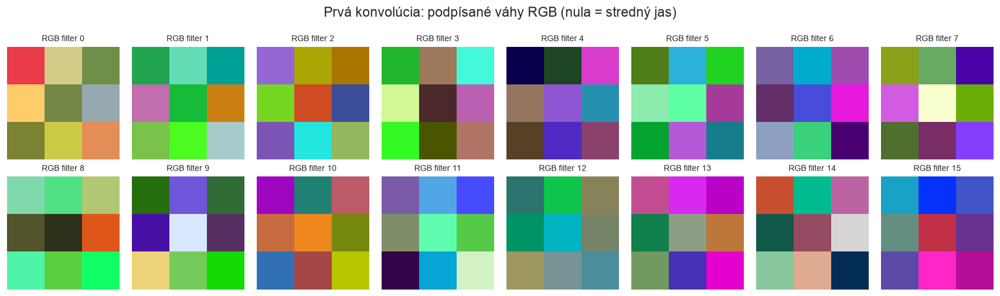

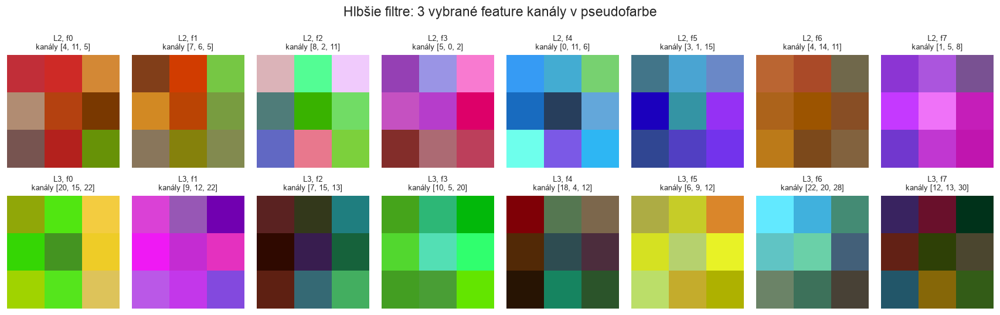

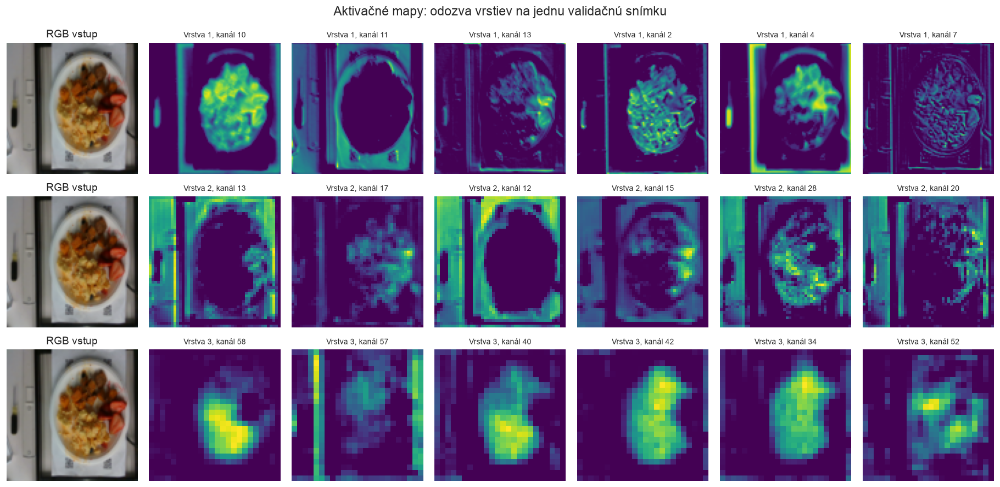

In [14]:
best_cnn=cnn_models[best_cnn_name].to(DEVICE).eval()
conv_layers=[m for m in best_cnn.features if isinstance(m,nn.Conv2d)]
# Prvá vrstva má skutočné vstupné kanály R, G, B.
w=conv_layers[0].weight.detach().cpu().numpy()
fig,axes=plt.subplots(int(np.ceil(len(w)/8)),8,figsize=(15,2.3*int(np.ceil(len(w)/8))),squeeze=False)
for i,ax in enumerate(axes.flat):
    ax.axis('off')
    if i<len(w):
        kernel=w[i].transpose(1,2,0);scale=max(float(np.abs(kernel).max()),1e-9)
        ax.imshow(np.clip(.5+kernel/(2*scale),0,1),interpolation='nearest');ax.set_title(f'RGB filter {i}',fontsize=9)
plt.suptitle('Prvá konvolúcia: podpísané váhy RGB (nula = stredný jas)');plt.tight_layout();plt.show()
# Hlbšia konvolúcia prijíma naučené feature mapy, nie RGB: tri najvýraznejšie
# vstupné kanály iba mapujeme na pseudofarby. Nezamieňame ich so skutočným RGB.
fig,axes=plt.subplots(len(conv_layers)-1,8,figsize=(15,5),squeeze=False)
for layer_id,conv in enumerate(conv_layers[1:]):
    ww=conv.weight.detach().cpu().numpy()
    for j,ax in enumerate(axes[layer_id]):
        selected=np.argsort(np.sum(ww[j]**2,axis=(1,2)))[-3:]
        kernel=ww[j,selected].transpose(1,2,0);scale=max(float(abs(kernel).max()),1e-9)
        ax.imshow(np.clip(.5+kernel/(2*scale),0,1),interpolation='nearest')
        ax.set_title(f'L{layer_id+2}, f{j}\nkanály {selected.tolist()}',fontsize=8);ax.axis('off')
plt.suptitle('Hlbšie filtre: 3 vybrané feature kanály v pseudofarbe');plt.tight_layout();plt.show()
# Pri skutočnej snímke zachytíme výstupy po ReLU; ukážeme najaktívnejšie mapy.
activation_maps={}; handles=[]
for i,layer in enumerate(best_cnn.features):
    if isinstance(layer,nn.ReLU):
        handles.append(layer.register_forward_hook(lambda m,inp,out,key=i:activation_maps.__setitem__(key,out.detach().cpu())))
x,_,idx=next(iter(image_loader('val')))
with torch.inference_mode():best_cnn(x[:1].to(DEVICE))
for handle in handles:handle.remove()
fig,axes=plt.subplots(3,7,figsize=(16,8))
for row,(layer_idx,activation) in enumerate(activation_maps.items()):
    axes[row,0].imshow(rgb_small[int(idx[0])]);axes[row,0].set_title('RGB vstup');axes[row,0].axis('off')
    most_active=activation[0].mean((1,2)).argsort(descending=True)[:6]
    for col,ch in enumerate(most_active,1):
        axes[row,col].imshow(activation[0,ch],cmap='viridis');axes[row,col].set_title(f'Vrstva {row+1}, kanál {ch.item()}',fontsize=9);axes[row,col].axis('off')
plt.suptitle('Aktivačné mapy: odozva vrstiev na jednu validačnú snímku');plt.tight_layout();plt.show()

**Čo, prečo a ako:** prvé filtre majú rozmer 3 × 3 × 3 a zobrazujeme ich farebne. Nulová váha je stredný jas; odchýlka znamená kladné alebo záporné váženie príslušnej farby. Súbežný svetlý a tmavý pás zachytáva smerový prechod, odlišné odtiene ukazujú farebný kontrast. Pri individuálnej normalizácii nemožno z jasu porovnávať absolútnu silu rôznych filtrov.

Hlbšie vrstvy prijímajú naučené mapy, preto ich vstupné osi už nie sú červená, zelená a modrá. Farebný pohľad používa tri vstupné kanály s najväčšou energiou váh a je označený ako **pseudofarba**. Ukážka ôsmich filtrov z každej hlbšej vrstvy slúži na čitateľnosť. Nižšie aktivačné mapy zobrazujú skutočnú odozvu na validačnú snímku: skoré mapy majú jemnejšie detaily, hlbšie väčšie receptívne polia a hrubšiu štruktúru.

**Ako to interpretovať:** filter nie je automaticky detektor konkrétnej ingrediencie. Identifikácia „mäso“ či „šalát“ len z farebného jadra by bola neodôvodnená. Kombinácia jadra, aktivácie a viditeľnej časti taniera podporuje opatrný opis farebných prechodov, okrajov riadu a textúr.

**Konkrétne príklady z vybranej CNN:** filter 8 má v hornom a dolnom riadku výraznejší zelený príspevok, zatiaľ čo stredný riadok obsahuje tmavšie váhy a odlišný červený príspevok vpravo. Zodpovedá to citlivosti na lokálny pásový a farebný kontrast. Filter 9 má jasnejší stred oproti viacerým tmavým susedom, teda môže zvýrazňovať rozdiel stred–okolie. Filter 15 má odlišné červené a modré príspevky v strednej a hornej časti jadra a môže reagovať na priestorové farebné prechody. Ide o opis naučených váh, nie dokázanú sémantickú funkciu. Následná BatchNorm a ReLU odozvu ďalej menia; preto prikladáme aj aktivačné mapy.

**Aktivácie na konkrétnom obrázku:** v prvej vrstve má kanál 10 silnú odozvu na ploche jedla, zatiaľ čo kanál 11 zvýrazňuje skôr pozadie a okraj taniera. V druhej vrstve kanály 12 a 13 výrazne reagujú aj na konštrukciu snímacieho zariadenia. V tretej vrstve majú napríklad kanály 58 a 42 hrubšiu odozvu vo vnútri porcie, ale kanál 57 zachováva odozvu aj pri bočných okrajoch záberu. Sieť teda reprezentuje aj pozadie; to je riziko prenosu na inú jedáleň alebo kameru, nie dôkaz, že pozadie priamo určuje finálne kalórie.

## 11. Použitie finálneho modelu na jednej fotografii

In [15]:
def predict_calories(image_path):
    """Odhad z RGB fotografie pomocou validačne vybraného transfer regresora."""
    with Image.open(image_path) as image:
        x=imagenet_preprocess(ImageOps.exif_transpose(image).convert('RGB')).unsqueeze(0)
    backbone.eval()
    with torch.inference_mode(): z=backbone(x.to(DEVICE)).cpu().numpy()
    if best_transfer_name=='MLP':
        scaled=feature_scaler.transform(z).astype(np.float32)
        mlp.eval()
        with torch.inference_mode(): result=mlp(torch.from_numpy(scaled).to(DEVICE)).item()*y_std+y_mean
    else:
        result=float(transfer_models[best_transfer_name].predict(z)[0])
        if best_transfer_name.startswith('SVR'):result=result*y_std+y_mean
    return float(result)
example_idx=int(SPLITS['test'][0])
example_prediction=predict_calories(df.at[example_idx,'path'])
assert np.isclose(example_prediction,all_predictions[(best_transfer_name,'test')][0],atol=.02)
print('Kontrola jednej snímky:',df.at[example_idx,'file_name'],'| odhad:',round(example_prediction,1),'kcal')

Kontrola jednej snímky: images/dish_1557853314.png | odhad: 130.0 kcal


**Čo, prečo a ako:** funkcia používa presne ten istý preprocessing, extraktor aj regresor ako vyhodnotenie. Nečíta kalorickú hodnotu, ingrediencie ani názov kategórie. Automatická kontrola porovná jednu predikciu s hromadným testovým vyhodnotením, čím overí konzistentnosť inferencie.

Výsledok je bodový odhad pre rozdelenie podobné školským dátam. Neznámy riad, iné osvetlenie, reštaurácia alebo fotografia zboku môžu chybu výrazne zmeniť. Funkcia nepredstavuje meranie energie ani individuálne garantovaný interval. Toto je kontrola existujúcej testovej snímky; nepovinnú databázu vlastných fotografií sme podľa zvoleného rozsahu nevytvárali.

## 12. Výsledky a záver overeného behu

Všetkých **3 260 RGB snímok** prešlo kontrolou párovania a rozdelením 2 328 / 466 / 466. Modely nedostali žiadne nutričné vstupy; kalorická hodnota slúžila výhradne ako cieľ. Podozrivú anotáciu s 2 991 g ryže sme po rozhodnutí pri audite ponechali a porovnali aj robustný Huberov tréning.

**Vlastná CNN:** validačne vyhrala **C1 základ** s checkpointom z epochy 103. Na tréningu má MAE 65.69 kcal, na validácii 72.60 kcal a na teste 76.93 kcal. Testové RMSE je 108.51 kcal a R² 0.725. Oproti baseline s testovým MAE 165.65 kcal sa sieť naučila užitočnú obrazovú informáciu. Rozdiely tréningu, validácie a testu treba čítať spolu s krivkami; dosiahnutá chyba neznamená bezchybné rozpoznávanie zloženia ani presnej gramáže.

**Vplyv extrému:** jediný podozrivý tréningový záznam tvorí 40.9 % súčtu štvorcov tréningových reziduálov vybranej CNN. Tréningové RMSE na všetkých dátach je 116.07 kcal; pri čisto diagnostickom vynechaní tohto jediného reziduálu by bolo 89.22 kcal. Model sa pre túto analýzu nepreučil, údaje sa neopravili a všetky oficiálne tabuľky stále zahŕňajú celý tréning. Väčšie tréningové RMSE než testové preto nemusí znamenať lepší testový fit – test tento extrém neobsahuje.

**Prenos vedomostí:** víťazom je **SVR C=1**. Na teste má MAE **61.18 kcal**, RMSE **87.49 kcal**, MSE **7654.76 kcal²** a R² **0.821**. Oproti vybranej vlastnej CNN znížil MAE o **20.5 %** a zlepšil aj kvadratickú chybu a R². ImageNet príznaky priniesli všeobecné informácie o textúrach, tvaroch a objektoch, ktoré sa pri malej tréningovej množine učia od nuly ťažšie. Toto je vysvetlenie podporené porovnaním, nie izolovaný dôkaz, že rozdiel spôsobilo len predtrénovanie; líšia sa aj vstupné rozlíšenia a regresory.

**Transformer:** malý ViT trénovaný priamo z RGB obrázkov dosiahol testové MAE 87.31 kcal, RMSE 125.02 kcal a R² 0.635. Neprekonal vybranú CNN v MAE a neprekonal transferový model. Na 2 328 tréningových snímkach je učenie globálnych obrazových vzťahov bez predtrénovania náročné; samotná zložitejšia architektúra nezaručuje lepší výsledok.

**Kde sa model mýli:** vysokokalorické jedlá majú pri transfere MAE 99.41 kcal oproti 37.09 kcal pri nízkokalorických. Obrázok zachytí viditeľnú plochu a farbu, ale nie priamo hmotnosť, objem ani skrytý tuk. Detailné fotografie najväčších chýb a ich anotácie sú v časti 9. Znamienko reziduálov a energetické pásma odlišujú náhodný rozptyl od systematického podhodnocovania či nadhodnocovania.

**Zhlukovanie a filtre:** opis všetkých zhlukov, priemerné RGB obrázky, ingrediencie a priemerné kalórie sú v časti 5. Zhluky sme vytvorili výlučne z obrazových príznakov. Farebné filtre prvej CNN vrstvy a aktivácie ukazujú farebné prechody a priestorové štruktúry; hlbšie pseudofarebné filtre nemožno stotožniť s RGB ani automaticky pomenovať ako ingrediencie.

**Praktický záver:** pre ďalšiu inferenciu používame validačne zvolený transferový model. Výsledok je odhad pre snímky podobné tomuto datasetu, s priemernou chybou vyčíslenou vyššie. Ďalšie zlepšenie by si vyžadovalo overenie podozrivých anotácií a meranie objemu alebo hĺbky; také informácie v tomto zadaní nie sú povolenými vstupmi.
